<a href="https://colab.research.google.com/github/Brown-Brayden/Problem-Set-5-Econ_3916_PS5/blob/main/Econ_3916_PS5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS5 — The Vendor's 93%

**ECON 3916 · Applied Data Analytics** · Problem Set 5 · 100 points · my role: model risk analyst, consumer lending

A vendor's default model is sold on "93% accuracy", and 93% of applications do not default. This notebook works out what that number is worth and answers the question the vendor did not ask: at what predicted probability of default should the lender decline?

- **Phase 1** simulates 20,000 applications whose true default process is known, then builds the null model the vendor's number cannot be told apart from.
- **Phase 2** fits plain, LASSO and Ridge logistic regressions and a random forest, and checks each against the truth.
- **Phase 3** moves past accuracy, puts a price on each kind of error, and finds the threshold that minimises expected cost.
- **Phase 4** tests two of those claims with an AI co-pilot: the transcript is at the end.

Every finding is in a text cell under the output it rests on. **To run:** Google Colab, *Runtime › Run all*. One seeded generator; a few minutes end to end, mostly the forest and its permutation importance. Everything used is already installed in Colab.

## Setup

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import statsmodels.api as sm
from scipy import stats, optimize
from scipy.special import expit, logit
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)

# Newer scikit-learn releases flag LogisticRegression(penalty=...) as deprecated. The fits are identical; this hides the notice.
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
rng = np.random.default_rng(SEED)     # one generator for the simulation, so every draw reruns the same way
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)

# Chart colours: a fixed, colour-blind-checked order. The five real features take slots 1-5; noise features are grey.
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
GREY, INK, INK_2 = "#9a9a96", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": INK_2,
                     "axes.titleweight": "bold", "lines.linewidth": 2, "legend.frameon": False})

## Phase 1: Build the Baseline Nobody Built (15 pts)

### Step 1.1: The data (8 pts)

In [2]:
# ---- The data-generating process (Step 1.1). These numbers are the truth Phase 2 is checked against. ----
N_APPS     = 20_000
PREVALENCE = 0.07           # the intercept is solved so the true default probability averages exactly this

REAL  = ["income_k", "dti_pct", "credit_history_yrs", "prior_delinquencies", "loan_amount_k"]
NOISE = ["application_hour", "months_at_address", "num_dependents", "form_fill_secs", "branch_code", "has_landline"]
FEATURES = REAL + NOISE     # 11 features, always in this order

# True effects on the log-odds of default
B_LOG_INCOME  = -0.80   # per unit of log(income / USD 62k)
B_DTI         = 0.055   # per percentage point of debt-to-income
B_DTI_OVER_40 = 0.080   # extra per point above 40%: risk climbs faster once debt service is heavy
B_LOG_HISTORY = -0.70   # per unit of log(credit history / 12 years)
B_DELINQ      = 0.60    # per prior delinquency, counted up to 4
B_LOG_LTI     = 0.50    # per unit of log(loan-to-income / 0.25): the ONLY causal effect of loan size
B_STRESS      = 0.80    # per SD of hidden financial stress: never observed, never a feature


def true_log_odds(d, stress, b0=0.0):
    """Log-odds of default from the five real features and the hidden stress. The six noise columns do not enter."""
    lti = d["loan_amount_k"] / d["income_k"]
    return (b0
            + B_LOG_INCOME * np.log(d["income_k"] / 62)
            + B_DTI * (d["dti_pct"] - 28) + B_DTI_OVER_40 * np.maximum(d["dti_pct"] - 40, 0)
            + B_LOG_HISTORY * np.log(d["credit_history_yrs"] / 12)
            + B_DELINQ * np.minimum(d["prior_delinquencies"], 4)
            + B_LOG_LTI * np.log(lti / 0.25)
            + B_STRESS * stress)


def simulate_applications(n, gen):
    d = pd.DataFrame(index=pd.RangeIndex(n, name="app_id"))
    stress = gen.standard_normal(n)                     # hidden: raises default risk AND what the applicant asks for
    d["income_k"]            = np.exp(gen.normal(np.log(62), 0.45, n))                    # USD k a year, right-skewed
    d["dti_pct"]             = np.clip(gen.normal(28, 9, n) + 3 * stress, 1, 70)          # existing debt payments / income, %
    d["credit_history_yrs"]  = np.clip(gen.gamma(3.0, 4.0, n), 0.5, 45)                   # years since first credit line
    d["prior_delinquencies"] = gen.poisson(0.35 * np.exp(0.5 * stress))                   # 60+ day lates on file
    d["loan_amount_k"]       = np.clip(d["income_k"] * np.exp(np.log(0.25) + 0.35 * gen.standard_normal(n)
                                                              + 0.25 * stress), 1, 150)   # USD k requested
    # Six fields a vendor might hand over that have nothing to do with default, or with anything else here
    d["application_hour"]    = gen.integers(0, 24, n)                                     # hour the form was submitted
    d["months_at_address"]   = np.round(gen.gamma(2.0, 30.0, n))
    d["num_dependents"]      = np.minimum(gen.poisson(1.0, n), 6)
    d["form_fill_secs"]      = np.round(np.exp(gen.normal(np.log(420), 0.5, n)))         # seconds spent on the form
    d["branch_code"]         = gen.integers(1, 61, n)                                     # 60 branches, stored as a number
    d["has_landline"]        = gen.binomial(1, 0.30, n)

    eta = true_log_odds(d, stress)
    b0 = optimize.brentq(lambda b: expit(b + eta).mean() - PREVALENCE, -20, 5)
    d["_stress"]  = stress                               # hidden columns start with _ and never enter X
    d["_true_pd"] = expit(b0 + eta)
    d["default"]  = gen.binomial(1, d["_true_pd"].to_numpy())
    return d, b0


apps, B0 = simulate_applications(N_APPS, rng)
X, y = apps[FEATURES], apps["default"]

# ---- Split FIRST. Everything below is fitted on train; every performance number reported is scored on test. ----
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
hidden_test = apps.loc[X_test.index, ["_stress", "_true_pd"]]    # the truth for the test rows, used only to check claims

print(f"{len(apps):,} applications -> {len(X_train):,} train / {len(X_test):,} test (stratified on default)")
print(f"Default rate: train {y_train.mean():.2%} ({y_train.sum()} defaults), test {y_test.mean():.2%} ({y_test.sum()} defaults)")
print(f"Intercept solved for a 7% true default probability: b0 = {B0:.3f}")
print("\nTraining rows only:")
desc = X_train.describe().T[["mean", "std", "min", "50%", "max"]]
desc["n_unique"] = X_train.nunique()
desc["truth"] = np.where(desc.index.isin(REAL), "real", "noise")
display(desc)

20,000 applications -> 14,000 train / 6,000 test (stratified on default)
Default rate: train 7.07% (990 defaults), test 7.08% (425 defaults)
Intercept solved for a 7% true default probability: b0 = -3.904

Training rows only:


,mean,std,min,50%,max,n_unique,truth
income_k,68.7850,32.9037,12.2828,62.0717,390.2157,14000,real
dti_pct,27.8812,9.4141,1.0000,27.8632,70.0000,13960,real
credit_history_yrs,11.9423,6.8857,0.5000,10.6197,45.0000,13985,real
prior_delinquencies,0.3981,0.6629,0.0000,0.0000,6.0000,7,real
loan_amount_k,18.9457,13.3546,1.2272,15.4378,150.0000,13998,real
application_hour,11.5517,6.9500,0.0000,12.0000,23.0000,24,noise
months_at_address,60.0914,42.3771,0.0000,50.0000,326.0000,269,noise
num_dependents,1.0048,1.0097,0.0000,1.0000,6.0000,7,noise
form_fill_secs,478.8557,256.2570,62.0000,424.0000,3092.0000,1270,noise
branch_code,30.4592,17.3146,1.0000,31.0000,60.0000,60,noise


**The data-generating process (the truth Phase 2 is checked against).** There are 20,000 applications, one row each, drawn by `simulate_applications` from the notebook's single seeded generator. The probability that application *i* defaults is

$$\text{logit}\,P(\text{default}_i) = b_0 - 0.80\ln\tfrac{\text{income}_i}{62} + 0.055\,(\text{DTI}_i - 28) + 0.080\max(\text{DTI}_i - 40,\,0) - 0.70\ln\tfrac{\text{history}_i}{12} + 0.60\min(\text{delinq}_i,\,4) + 0.50\ln\tfrac{\text{loan}_i/\text{income}_i}{0.25} + 0.80\,S_i$$

where $b_0 = -3.904$ is solved so that the true probability averages exactly 7%.

| Feature | Units | How it is drawn | Role in default |
|---|---|---|---|
| `income_k` | USD k a year | lognormal, median 62, log-SD 0.45 | −0.80 per log unit: more income, less risk |
| `dti_pct` | % of income | N(28, 9²) + 3·S, clipped to 1–70 | +0.055 per point, and a further +0.080 per point above 40%: **a kink a straight line can't fit** |
| `credit_history_yrs` | years | gamma(3, 4), mean 12 | −0.70 per log unit: longer history, less risk |
| `prior_delinquencies` | count | Poisson, mean 0.35·e^(0.5·S) | +0.60 each, up to 4 |
| `loan_amount_k` | USD k | income × lognormal (median 0.25, log-SD 0.35) × e^(0.25·S) | +0.50 per log unit of loan-to-income: **the only causal effect of loan size** |
| `application_hour` | 0–23 | uniform whole numbers | none |
| `months_at_address` | months | gamma(2, 30), rounded | none |
| `num_dependents` | count | Poisson(1), capped at 6 | none |
| `form_fill_secs` | seconds | lognormal, median 420 | none |
| `branch_code` | 1–60 | uniform whole numbers, stored as a number | none |
| `has_landline` | 0/1 | Bernoulli(0.3) | none |

**The hidden variable.** $S$ is each applicant's financial stress, drawn N(0, 1). It is never a column a model sees. It raises default risk directly, by +0.80 per SD. It also moves three things the model does see: stressed applicants carry more debt, have more past delinquencies, and ask for bigger loans relative to their income. That last link is deliberate. It means loan size predicts default for two reasons, and a lender can act on only one of them. Step 2.2 comes back to it.

**The split comes first.** The 30% test set (6,000 applications, 425 of them defaults) is set aside before anything is summarised, and the table above describes training rows only. The split is stratified, so the default rate is 7.07% in training (990 defaults) and 7.08% in test. Cross-validation, out-of-bag scores and every tuning choice use training rows only. Every performance number from here on is scored on the test set.

### Step 1.2: The null model (7 pts)

In [3]:
null = DummyClassifier(strategy="prior").fit(X_train, y_train)   # predicts "no default" for everyone; its probability is the training default rate
null_pred = null.predict(X_test)
null_prob = null.predict_proba(X_test)[:, 1]
null_acc  = accuracy_score(y_test, null_pred)

n_test, n_def = len(y_test), int(y_test.sum())
n_good = n_test - n_def
print(f"Null model ('nobody defaults') on the {n_test:,} test applications")
print(f"  accuracy               {null_acc:.4f}")
print(f"  defaults caught        0 of {n_def}   (recall {recall_score(y_test, null_pred):.2f})")
print(f"  applications declined  {int(null_pred.sum())}")
print(f"\nTo beat {null_acc:.2%} on accuracy, a model must flag more defaulters than good applicants:")
print("each flagged defaulter is +1 correct against the null, each flagged good applicant is -1.")

Null model ('nobody defaults') on the 6,000 test applications
  accuracy               0.9292
  defaults caught        0 of 425   (recall 0.00)
  applications declined  0

To beat 92.92% on accuracy, a model must flag more defaulters than good applicants:
each flagged defaulter is +1 correct against the null, each flagged good applicant is -1.


**The floor is 92.92%.** The null model approves every application. On the test set it is right 92.92% of the time, because that is the share of applicants who repay: 425 of the 6,000 default. It catches no defaults and declines nobody.

**Why the vendor's 93% says nothing yet.** Score any model on the same rows as the null. The two answers differ only on the applicants the model flags. Each flagged applicant who defaults gives the model one more correct answer than the null; each flagged applicant who repays costs it one. So a model beats the null's accuracy **only if more than half of the applicants it flags actually default.** A model that flags nobody ties the null. A useful model that flags 300 applicants, 30% of whom default, *loses* to the null on accuracy even though it catches 90 defaults. Accuracy cannot tell these apart, so the rest of this notebook measures something else.

**The sentence for the meeting:** "A model that approves every application and has learned nothing scores 92.9% on our test set; that is the vendor's number, so before we sign we need to see how many defaults the model catches and what its mistakes cost us."

## Phase 2: Fit and Regularise (30 pts)

### Step 2.1: Logistic regression, then penalised (20 pts)

In [4]:
# Standardise with the training means and SDs, so every coefficient below is "log-odds per SD" and comparable.
scaler  = StandardScaler().fit(X_train)
Z_train = pd.DataFrame(scaler.transform(X_train), index=X_train.index, columns=FEATURES)
Z_test  = pd.DataFrame(scaler.transform(X_test),  index=X_test.index,  columns=FEATURES)

plain   = sm.Logit(y_train, sm.add_constant(Z_train)).fit(disp=0)     # ordinary maximum-likelihood logistic regression
p_plain = plain.predict(sm.add_constant(Z_test)).to_numpy()

plain_tab = pd.DataFrame({"truth": np.where(np.isin(FEATURES, REAL), "real", "noise"),
                          "coef_per_SD": plain.params[FEATURES].to_numpy(),
                          "std_err": plain.bse[FEATURES].to_numpy(),
                          "p_value": plain.pvalues[FEATURES].to_numpy()}, index=FEATURES)
print(f"Plain logistic regression: {len(FEATURES)} features, {len(X_train):,} training applications")
display(plain_tab)
sig_noise = plain_tab.query("truth == 'noise' and p_value < 0.05").index.tolist()
weak_real = plain_tab.query("truth == 'real' and p_value >= 0.05").index.tolist()
print(f"Noise features with p < 0.05: {sig_noise if sig_noise else 'none'}")
print(f"Real features with p >= 0.05: {weak_real if weak_real else 'none'}")

Plain logistic regression: 11 features, 14,000 training applications


,truth,coef_per_SD,std_err,p_value
income_k,real,-1.0371,0.0666,1.2106e-54
dti_pct,real,0.8286,0.0389,1.1418e-100
credit_history_yrs,real,-0.4036,0.0421,8.8282e-22
prior_delinquencies,real,0.5501,0.0278,3.0978e-87
loan_amount_k,real,0.6251,0.0469,1.5349e-40
application_hour,noise,-0.0096,0.0357,7.8878e-01
months_at_address,noise,-0.0530,0.0366,1.4724e-01
num_dependents,noise,-0.0041,0.0358,9.0833e-01
form_fill_secs,noise,0.0833,0.0341,1.4484e-02
branch_code,noise,-0.0312,0.0361,3.8773e-01


Noise features with p < 0.05: ['form_fill_secs']
Real features with p >= 0.05: none


In [5]:
# ---- LASSO (L1) and Ridge (L2) logistic regression over a grid of penalty strengths, chosen by 5-fold CV ----
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
Cs = np.logspace(-5, 1, 25)        # C = 1 / penalty strength: small C = heavy penalty, large C = almost none


def penalised(penalty, C=1.0):
    """Scaler inside the pipeline, so each CV fold is standardised on its own training rows."""
    solver = "saga" if penalty == "l1" else "lbfgs"
    return make_pipeline(StandardScaler(),
                         LogisticRegression(penalty=penalty, C=C, solver=solver, max_iter=5000, random_state=SEED))


searches, cv_curves, paths = {}, {}, {}
for name, pen in [("LASSO", "l1"), ("Ridge", "l2")]:
    # Log loss, not accuracy, picks the penalty: accuracy barely moves off the null's at 7% prevalence.
    gs = GridSearchCV(penalised(pen), {"logisticregression__C": Cs}, cv=cv, scoring="neg_log_loss", n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    cvr = pd.DataFrame(gs.cv_results_)
    cv_curves[name] = pd.DataFrame({"C": cvr["param_logisticregression__C"].astype(float).to_numpy(),
                                    "cv_log_loss": -cvr["mean_test_score"].to_numpy(),
                                    "se": cvr["std_test_score"].to_numpy() / np.sqrt(cv.get_n_splits())})
    # The coefficient path: refit on all training rows at every C
    paths[name] = pd.DataFrame([penalised(pen, C).fit(X_train, y_train)[-1].coef_.ravel() for C in Cs],
                               index=Cs, columns=FEATURES)

lasso, ridge = searches["LASSO"].best_estimator_, searches["Ridge"].best_estimator_
C_lasso = searches["LASSO"].best_params_["logisticregression__C"]
C_ridge = searches["Ridge"].best_params_["logisticregression__C"]

# One-standard-error rule: the heaviest penalty whose CV log loss is within one SE of the best
lc = cv_curves["LASSO"]
best_row = lc["cv_log_loss"].idxmin()
C_1se = lc.loc[lc["cv_log_loss"] <= lc.loc[best_row, "cv_log_loss"] + lc.loc[best_row, "se"], "C"].min()
lasso_1se = penalised("l1", C_1se).fit(X_train, y_train)

coefs = pd.DataFrame({"truth": np.where(np.isin(FEATURES, REAL), "real", "noise"),
                      "plain": plain.params[FEATURES].to_numpy(),
                      "LASSO (CV min)": lasso[-1].coef_.ravel(),
                      "LASSO (1-SE)": lasso_1se[-1].coef_.ravel(),
                      "Ridge (CV min)": ridge[-1].coef_.ravel()}, index=FEATURES)
print(f"LASSO: CV minimum at C = {C_lasso:.4g}; one-SE rule C = {C_1se:.4g}.   Ridge: CV minimum at C = {C_ridge:.4g}")
print(f"Best 5-fold CV log loss: LASSO {lc['cv_log_loss'].min():.5f}, Ridge {cv_curves['Ridge']['cv_log_loss'].min():.5f}, "
      f"intercept only {lc['cv_log_loss'].iloc[0]:.5f}")
print("Coefficients, log-odds per SD of each feature:")
display(coefs)

for label, col in [("CV-minimum LASSO", "LASSO (CV min)"), ("One-SE LASSO", "LASSO (1-SE)")]:
    zeroed = coefs.index[coefs[col] == 0].tolist()
    found = [f for f in zeroed if f in NOISE]
    lost = [f for f in zeroed if f in REAL]
    kept_noise = [f for f in NOISE if f not in zeroed]
    print(f"\n{label}: driven to exactly zero -> {zeroed}")
    print(f"  noise features found: {len(found)} of {len(NOISE)};  real features discarded: {len(lost)} of {len(REAL)} {lost if lost else ''}")
    print(f"  noise it kept: {kept_noise if kept_noise else 'none'}")
print(f"\nRidge: coefficients exactly zero -> {int((coefs['Ridge (CV min)'] == 0).sum())} of {len(FEATURES)}; "
      f"smallest |coef| {coefs['Ridge (CV min)'].abs().min():.4f}")

LASSO: CV minimum at C = 0.1778; one-SE rule C = 0.01778.   Ridge: CV minimum at C = 0.3162
Best 5-fold CV log loss: LASSO 0.20332, Ridge 0.20335, intercept only 0.25556
Coefficients, log-odds per SD of each feature:


,truth,plain,LASSO (CV min),LASSO (1-SE),Ridge (CV min)
income_k,real,-1.0371,-0.9992,-0.6937,-1.0202
dti_pct,real,0.8286,0.8202,0.7526,0.8254
credit_history_yrs,real,-0.4036,-0.3920,-0.2966,-0.4005
prior_delinquencies,real,0.5501,0.5453,0.5091,0.5493
loan_amount_k,real,0.6251,0.6005,0.3977,0.6143
application_hour,noise,-0.0096,-0.0025,0.0000,-0.0095
months_at_address,noise,-0.0530,-0.0452,0.0000,-0.0528
num_dependents,noise,-0.0041,0.0000,0.0000,-0.0042
form_fill_secs,noise,0.0833,0.0761,0.0127,0.0829
branch_code,noise,-0.0312,-0.0237,0.0000,-0.0311



CV-minimum LASSO: driven to exactly zero -> ['num_dependents']
  noise features found: 1 of 6;  real features discarded: 0 of 5 
  noise it kept: ['application_hour', 'months_at_address', 'form_fill_secs', 'branch_code', 'has_landline']

One-SE LASSO: driven to exactly zero -> ['application_hour', 'months_at_address', 'num_dependents', 'branch_code', 'has_landline']
  noise features found: 5 of 6;  real features discarded: 0 of 5 
  noise it kept: ['form_fill_secs']

Ridge: coefficients exactly zero -> 0 of 11; smallest |coef| 0.0042


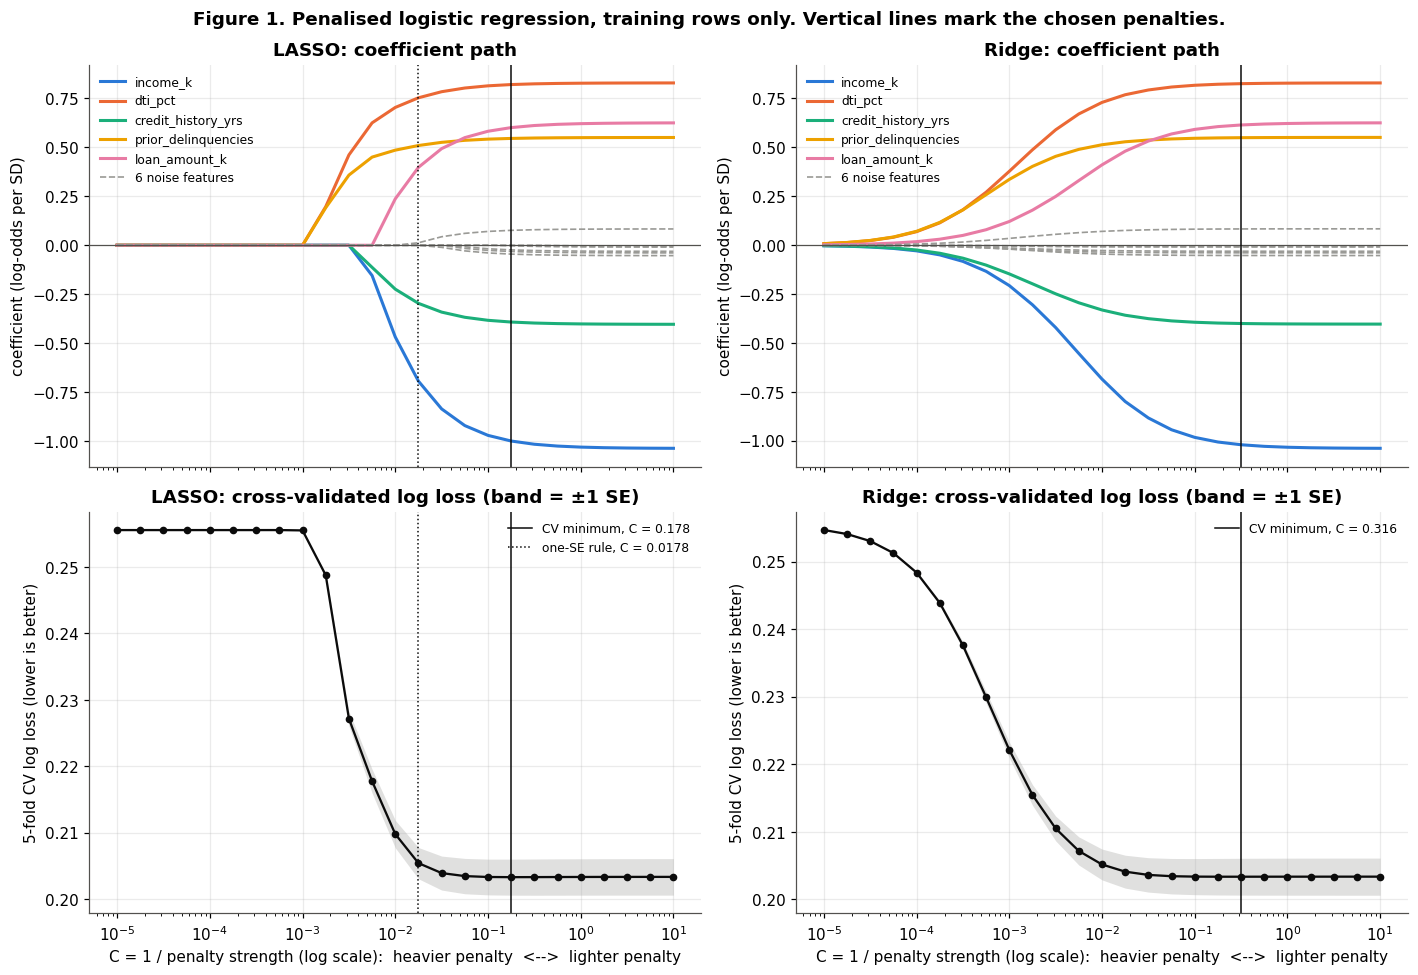

In [6]:
# ---- Figure 1: coefficient paths and the CV curves that pick the penalty ----
REAL_COLOURS = dict(zip(REAL, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]))
chosen = {"LASSO": C_lasso, "Ridge": C_ridge}

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
for col, name in enumerate(["LASSO", "Ridge"]):
    ax = axes[0, col]
    for f in FEATURES:
        if f in REAL:
            ax.plot(paths[name].index, paths[name][f], color=REAL_COLOURS[f], lw=2, label=f)
        else:
            ax.plot(paths[name].index, paths[name][f], color=GREY, lw=1.1, ls="--")
    ax.plot([], [], color=GREY, lw=1.1, ls="--", label=f"{len(NOISE)} noise features")
    ax.axhline(0, color=INK_2, lw=0.8)
    ax.axvline(chosen[name], color=INK, lw=1)
    if name == "LASSO":
        ax.axvline(C_1se, color=INK, lw=1, ls=":")
    ax.set_xscale("log")
    ax.set_ylabel("coefficient (log-odds per SD)")
    ax.set_title(f"{name}: coefficient path")
    ax.legend(fontsize=8, loc="upper left")

    ax = axes[1, col]
    cc = cv_curves[name]
    ax.plot(cc["C"], cc["cv_log_loss"], color=INK, lw=1.5, marker="o", ms=4)
    ax.fill_between(cc["C"], cc["cv_log_loss"] - cc["se"], cc["cv_log_loss"] + cc["se"], color=GREY, alpha=0.3, lw=0)
    ax.axvline(chosen[name], color=INK, lw=1, label=f"CV minimum, C = {chosen[name]:.3g}")
    if name == "LASSO":
        ax.axvline(C_1se, color=INK, lw=1, ls=":", label=f"one-SE rule, C = {C_1se:.3g}")
    ax.set_xscale("log")
    ax.set_xlabel("C = 1 / penalty strength (log scale):  heavier penalty  <-->  lighter penalty")
    ax.set_ylabel("5-fold CV log loss (lower is better)")
    ax.set_title(f"{name}: cross-validated log loss (band = ±1 SE)")
    ax.legend(fontsize=8, loc="upper right")
fig.suptitle("Figure 1. Penalised logistic regression, training rows only. Vertical lines mark the chosen penalties.",
             fontweight="bold")
plt.tight_layout()
plt.show()

In [7]:
# ---- Test-set scorecard for the logistic family (the forest joins it in Step 2.2) ----
def scorecard(y_true, prob, thr=0.5):
    """Hard decisions at prob > thr (the rule .predict() uses at 0.5), plus threshold-free scores."""
    y_true, prob = np.asarray(y_true), np.asarray(prob)
    pred = (prob > thr).astype(int)
    return {"accuracy": accuracy_score(y_true, pred),
            "vs null (pp)": 100 * (accuracy_score(y_true, pred) - null_acc),
            "flagged": int(pred.sum()),
            "defaults caught": int(((pred == 1) & (y_true == 1)).sum()),
            "ROC AUC": roc_auc_score(y_true, prob),
            "PR AUC": average_precision_score(y_true, prob),
            "Brier": brier_score_loss(y_true, prob)}


def board_of(prob_dict):
    b = pd.DataFrame({k: scorecard(y_test, v) for k, v in prob_dict.items()}).T.astype(float)
    b[["flagged", "defaults caught"]] = b[["flagged", "defaults caught"]].astype(int)
    return b


p_lasso     = lasso.predict_proba(X_test)[:, 1]
p_lasso_1se = lasso_1se.predict_proba(X_test)[:, 1]
p_ridge     = ridge.predict_proba(X_test)[:, 1]
probs = {"null (approve all)": null_prob, "plain logistic": p_plain, "LASSO (CV min)": p_lasso,
         "LASSO (1-SE)": p_lasso_1se, "Ridge (CV min)": p_ridge}
print(f"Test set ({n_test:,} applications, {n_def} defaults); hard decisions at threshold 0.5")
display(board_of(probs))

Test set (6,000 applications, 425 defaults); hard decisions at threshold 0.5


,accuracy,vs null (pp),flagged,defaults caught,ROC AUC,PR AUC,Brier
null (approve all),0.9292,0.0000,0,0,0.5000,0.0708,0.0658
plain logistic,0.9317,0.2500,79,47,0.8230,0.3202,0.0561
LASSO (CV min),0.9313,0.2167,73,43,0.8232,0.3209,0.0561
LASSO (1-SE),0.9312,0.2000,40,26,0.8225,0.3231,0.0562
Ridge (CV min),0.9315,0.2333,78,46,0.8231,0.3202,0.0561


**Plain logistic regression.** All five real features come out with the right sign and overwhelming significance (p between 10⁻²² and 10⁻¹⁰⁰). Per SD, the coefficients are income −1.04, DTI +0.83, loan amount +0.63, prior delinquencies +0.55 and credit history −0.40. Five of the six noise features are correctly insignificant, but `form_fill_secs` gets p = 0.014 (+0.083 per SD). With six noise features each tested at 5%, the chance that at least one passes is 1 − 0.95⁶ = 26%, so this is unlucky but not surprising. A p-value screen would have kept a field with nothing to do with default, and the plain fit itself selects nothing: every noise feature gets a nonzero coefficient.

**What LASSO drove to exactly zero.** Cross-validated log loss picks C = 0.178 (Figure 1, bottom left). At that penalty LASSO sets **only `num_dependents`** to exactly zero.

- It finds **1 of the 6** noise features and discards **0 of the 5** real ones.
- The noise it keeps is `application_hour`, `months_at_address`, `form_fill_secs`, `branch_code` and `has_landline`. Their coefficients are small, 0.003 to 0.076 in absolute value per SD, against 0.39 for the weakest real feature (`credit_history_yrs`), but they are not zero.
- The *order* is right even where the selection is not. In Figure 1 (top left) all five real features leave zero between C ≈ 0.001 and 0.01; the first noise feature, `form_fill_secs`, leaves it only after C ≈ 0.01.
- The one-SE rule (C = 0.0178) is the heaviest penalty whose CV loss is within one standard error of the best. It zeros every noise feature except `form_fill_secs`: **5 of 6** noise found, **0 of 5** real discarded. The one it misses is the feature the plain fit's p-value wrongly flagged: in this sample, `form_fill_secs` happens to line up with default.

**Why the CV choice keeps some noise.** Cross-validation picks the penalty that *predicts* best, and a tiny coefficient on a noise feature costs almost nothing in log loss. So the prediction-optimal penalty is lighter than the one that would select the true feature set exactly. Here the CV curve is essentially flat for every C above about 0.05 (Figure 1, bottom left), so exactly where its minimum lands is close to arbitrary, and it lands where five noise features are still in. If the goal is a short list of fields to collect and defend, the one-SE rule is the better choice: it gives up almost no predictive accuracy and drops more noise.

**On the test set** (table above), the four logistic models are almost indistinguishable: ROC AUC 0.8225 to 0.8232, PR AUC 0.320 to 0.323, Brier 0.0561 to 0.0562. At the 0.5 threshold the CV-minimum LASSO flags 73 applicants and scores 93.13% accuracy, against 92.92% for the null. Of the 73 it flags, 43 default and 30 repay, so it beats the null by 43 − 30 = 13 correct answers out of 6,000. Every logistic model here beats the null by 0.20 to 0.25 points, and a headline accuracy could not tell any of them from a model that learned nothing. The rest of the notebook carries the CV-minimum LASSO forward as *the penalised logistic model*. Its CV log loss (0.20332) ties Ridge's (0.20335), and it is the one that hands back a shorter list of fields.

**Why Ridge shrinks but does not zero.** Both penalties add a charge for coefficient size to the log loss. They differ in how that charge behaves near zero.

- **Ridge charges λβ².** Its marginal cost, 2λβ, shrinks to nothing as β approaches zero. A feature with any signal at all, however faint, can therefore lower the total by more than the penalty costs at some small enough β. The optimum is small, but never exactly zero. Ridge pulls every coefficient toward zero together; in Figure 1 (top right) the eleven paths fan out from zero at once.
- **LASSO charges λ|β|.** Its marginal cost stays at λ however small β gets. A feature enters only if the log loss's pull on it at β = 0 is stronger than λ; if not, the best β is exactly zero. This is soft-thresholding. In Figure 1 (top left), coefficients sit flat at zero and leave it one at a time as the penalty weakens.
- **In pictures:** the L1 constraint region is a diamond with corners on the axes, and the loss contours usually first touch it at a corner, where some coefficients are zero. The L2 region is a ball with no corners.

**When I would use each.**

- **LASSO** when I believe only a few of the candidate fields matter and want the model to say which. A scorecard built on five fields instead of eleven is cheaper to run and easier to defend to a regulator. Every variable in it also has to be explainable in an adverse-action notice. That is this lender's situation. The weakness: among correlated features (income and loan amount move together here) LASSO keeps one more or less arbitrarily, and which one can change from sample to sample.
- **Ridge** when many features each carry a little signal, especially correlated ones. It shares the weight among them instead of choosing, which is more stable and often predicts slightly better, but it never simplifies the model.
- **Elastic net**, a mix of the two penalties, when I want selection but want correlated features kept or dropped together.

### Step 2.2: A model that is not linear (10 pts)

In [8]:
rf = RandomForestClassifier(n_estimators=500, oob_score=True, bootstrap=True, random_state=SEED, n_jobs=-1)
rf.fit(X_train, y_train)

p_rf     = rf.predict_proba(X_test)[:, 1]
oob_prob = rf.oob_decision_function_[:, 1]          # each training row scored only by the ~37% of trees that never saw it
acc_rf_test = accuracy_score(y_test, rf.predict(X_test))

print(f"Out-of-bag accuracy (training rows) {rf.oob_score_:.4f}    test accuracy {acc_rf_test:.4f}    null {null_acc:.4f}")
print(f"Out-of-bag ROC AUC                  {roc_auc_score(y_train, oob_prob):.4f}    test ROC AUC  {roc_auc_score(y_test, p_rf):.4f}")
print(f"Out-of-bag PR AUC                   {average_precision_score(y_train, oob_prob):.4f}    test PR AUC   {average_precision_score(y_test, p_rf):.4f}")

Out-of-bag accuracy (training rows) 0.9303    test accuracy 0.9303    null 0.9292
Out-of-bag ROC AUC                  0.7906    test ROC AUC  0.7938
Out-of-bag PR AUC                   0.2859    test PR AUC   0.2925


In [9]:
# ---- Forest against the penalised logistic model, on the same test rows ----
probs["random forest"] = p_rf
board = board_of(probs)
display(board)

d_acc = board.loc["random forest", "accuracy"] - board.loc["LASSO (CV min)", "accuracy"]
d_auc = board.loc["random forest", "ROC AUC"] - board.loc["LASSO (CV min)", "ROC AUC"]
d_pr  = board.loc["random forest", "PR AUC"] - board.loc["LASSO (CV min)", "PR AUC"]
print(f"Forest minus LASSO:  accuracy {100 * d_acc:+.2f} pp   ROC AUC {d_auc:+.4f}   PR AUC {d_pr:+.4f}")

,accuracy,vs null (pp),flagged,defaults caught,ROC AUC,PR AUC,Brier
null (approve all),0.9292,0.0000,0,0,0.5000,0.0708,0.0658
plain logistic,0.9317,0.2500,79,47,0.8230,0.3202,0.0561
LASSO (CV min),0.9313,0.2167,73,43,0.8232,0.3209,0.0561
LASSO (1-SE),0.9312,0.2000,40,26,0.8225,0.3231,0.0562
Ridge (CV min),0.9315,0.2333,78,46,0.8231,0.3202,0.0561
random forest,0.9303,0.1167,39,23,0.7938,0.2925,0.0577


Forest minus LASSO:  accuracy -0.10 pp   ROC AUC -0.0294   PR AUC -0.0284


**Out-of-bag against test.** The out-of-bag accuracy is 0.9303 and the test accuracy also 0.9303. Out-of-bag ROC AUC is 0.791 against 0.794 on test, and PR AUC 0.286 against 0.293. They should be close because both score each row only with trees that never saw it, on rows from the same population; a large gap would mean the test set is not like the training set (a shift, or a leak in the split), or that one of the two samples got lucky.

**Does the forest beat the penalised logistic model? No.** On every test-set measure the forest is worse than the CV-minimum LASSO:

| | accuracy | ROC AUC | PR AUC | Brier | flagged at 0.5 | defaults caught |
|---|---|---|---|---|---|---|
| LASSO (CV min) | 93.13% | 0.823 | 0.321 | 0.0561 | 73 | 43 |
| random forest | 93.03% | 0.794 | 0.293 | 0.0577 | 39 | 23 |

The same holds where the money is: in Phase 3 the forest's best threshold costs USD 658 per application, against USD 585 for the LASSO. That is no surprise. The true model is close to linear in log-odds: a smooth effect per feature plus one kink. With 990 training defaults, 500 fully grown trees approximate those smooth curves with steps and spend many of their splits on noise (next cell), while the LASSO spends one coefficient per feature. **The expensive model loses to the cheap one.** The cheap one is also the model the lender can explain to a regulator: one signed coefficient per field. Task 4.1 Part A tests whether the 0.10-point accuracy gap means anything.

,truth,distinct values (train),MDI,MDI rank,perm: test AUC drop,perm SD,perm rank
dti_pct,real,13960,0.1714,1,0.1047,0.0100,1
income_k,real,14000,0.1333,2,0.0625,0.0073,3
loan_amount_k,real,13998,0.1251,3,0.0476,0.0037,4
credit_history_yrs,real,13985,0.1226,4,0.0201,0.0052,5
form_fill_secs,noise,1270,0.1012,5,-0.0009,0.0025,10
months_at_address,noise,269,0.0902,6,-0.0030,0.0027,11
branch_code,noise,60,0.0822,7,0.0019,0.0030,7
application_hour,noise,24,0.0686,8,0.0030,0.0020,6
prior_delinquencies,real,7,0.0615,9,0.0656,0.0073,2
num_dependents,noise,7,0.0311,10,0.0005,0.0008,8


Share of MDI going to the 6 noise features: 38.6%
Sum of permutation importance on the 6 noise features: +0.0006 AUC (real features: +0.3004)


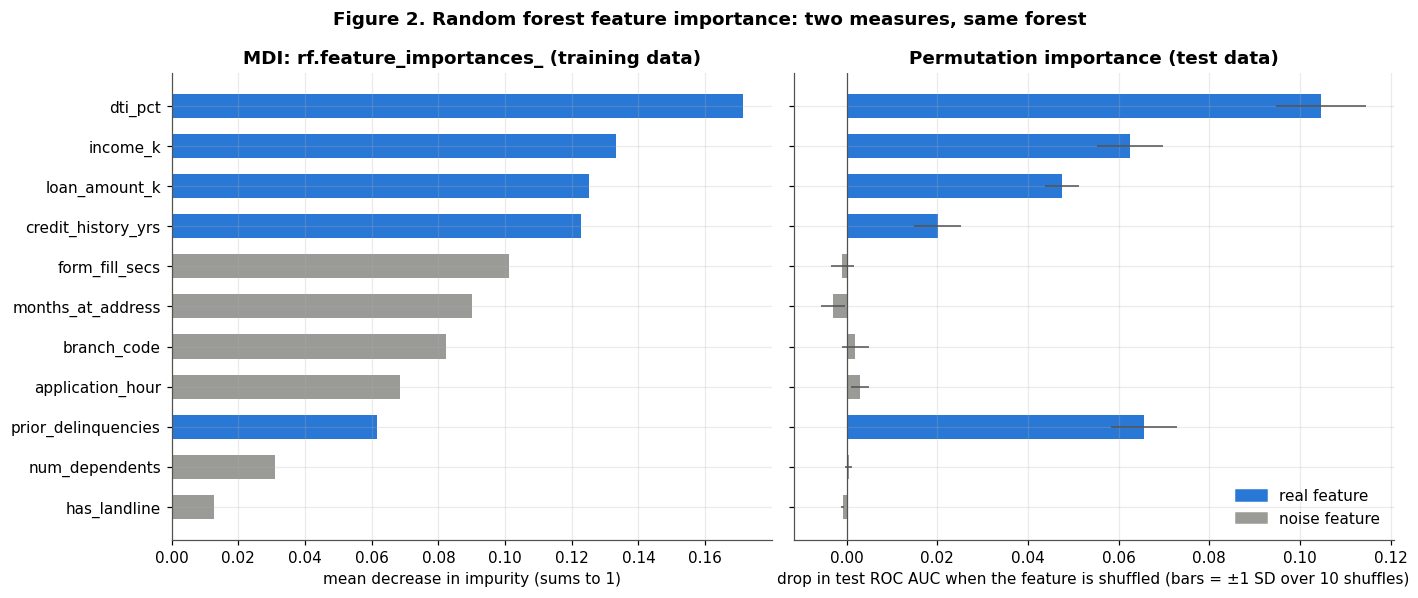

In [10]:
# ---- Two kinds of importance: MDI (training data, built into the forest) and permutation (test data) ----
mdi  = pd.Series(rf.feature_importances_, index=FEATURES)
perm = permutation_importance(rf, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED)   # about a minute
perm_mean = pd.Series(perm.importances_mean, index=FEATURES)

imp = pd.DataFrame({"truth": np.where(np.isin(FEATURES, REAL), "real", "noise"),
                    "distinct values (train)": X_train.nunique(),
                    "MDI": mdi,
                    "MDI rank": mdi.rank(ascending=False).astype(int),
                    "perm: test AUC drop": perm_mean,
                    "perm SD": pd.Series(perm.importances_std, index=FEATURES),
                    "perm rank": perm_mean.rank(ascending=False).astype(int)}).sort_values("MDI", ascending=False)
display(imp)
print(f"Share of MDI going to the 6 noise features: {mdi[NOISE].sum():.1%}")
print(f"Sum of permutation importance on the 6 noise features: {perm_mean[NOISE].sum():+.4f} AUC "
      f"(real features: {perm_mean[REAL].sum():+.4f})")

# Figure 2
order = imp.index[::-1]                                   # largest MDI at the top
bar_colours = [BLUE if f in REAL else GREY for f in order]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
axes[0].barh(order, imp.loc[order, "MDI"], color=bar_colours, height=0.6)
axes[0].set_title("MDI: rf.feature_importances_ (training data)")
axes[0].set_xlabel("mean decrease in impurity (sums to 1)")
axes[1].barh(order, imp.loc[order, "perm: test AUC drop"], xerr=imp.loc[order, "perm SD"], color=bar_colours,
             height=0.6, error_kw={"ecolor": INK_2, "lw": 1})
axes[1].axvline(0, color=INK_2, lw=0.8)
axes[1].set_title("Permutation importance (test data)")
axes[1].set_xlabel("drop in test ROC AUC when the feature is shuffled (bars = ±1 SD over 10 shuffles)")
axes[1].legend(handles=[Patch(color=BLUE, label="real feature"), Patch(color=GREY, label="noise feature")],
               loc="lower right")
fig.suptitle("Figure 2. Random forest feature importance: two measures, same forest", fontweight="bold")
plt.tight_layout()
plt.show()

**Where MDI and permutation importance disagree.** Sharply, and in the way the theory predicts (table and Figure 2):

- **MDI promotes noise.** It ranks four noise features (`form_fill_secs` 0.101, `months_at_address` 0.090, `branch_code` 0.082, `application_hour` 0.069) above the real `prior_delinquencies` (0.062), and gives the six noise features 38.6% of all importance.
- **Permutation importance does not.** Every noise feature is within 0.003 of zero (together +0.0006 of test AUC), against at least 0.020 for each real feature, and `prior_delinquencies` comes 2nd, behind only DTI.
- **Within the noise, MDI follows cardinality exactly.** The noise features rank in precisely the order of how many distinct values they take: `form_fill_secs` (1,270) > `months_at_address` (269) > `branch_code` (60) > `application_hour` (24) > `num_dependents` (7) > `has_landline` (2). None of them has any effect on default.
- **`prior_delinquencies` is the mirror image:** a strong real feature with only 7 distinct values, so few places to cut, and MDI ranks it 9th of 11.

**Why MDI inflates high-cardinality features.** MDI adds up, over every split in every tree, how much that split reduced impurity on the *training* rows that reached it. Three things push it toward features with many distinct values:

- **More cut points.** A continuous feature like `form_fill_secs` offers thousands of possible cut points; `has_landline` offers one. Deep in a tree, where nodes hold a handful of rows, the best of thousands of random cuts almost always separates a few defaults from a few repayers by chance. The forest takes that cut, and MDI credits the feature with the impurity it "removed".
- **Measured in-sample.** MDI is computed on the rows the trees were grown on. Splits that fit noise count as fully as splits that fit signal; nothing checks whether they hold up on new data.
- **Full-depth trees.** Grown to purity (the default), the trees keep splitting until every leaf is pure. A large share of the splits are therefore noise-fitting splits, and they go mostly to whichever features offer the most cut points.

Permutation importance asks a different question: on the *test* set, how much worse does the forest rank applicants when this column is shuffled? A feature whose splits only fit training noise loses nothing when shuffled, so its permutation importance sits at zero, give or take shuffle noise. That is why permutation importance is the one to report.

In [11]:
# ---- Importance is not effect: the lender's one real lever is the loan amount it offers ----
# Counter-offer instead of decline: what does each model predict if the lender halves the amount requested?
X_half = X_test.copy()
X_half["loan_amount_k"] = X_half["loan_amount_k"] / 2
stress_test = hidden_test["_stress"]
risky = p_lasso >= np.quantile(p_lasso, 0.90)          # the riskiest tenth by the LASSO model: the ones a lender considers declining

lever = {}
for group, mask in [("all test applicants", np.ones(n_test, dtype=bool)), ("riskiest 10% by LASSO", risky)]:
    lever[(group, "LASSO model")] = (p_lasso[mask].mean(), lasso.predict_proba(X_half)[mask, 1].mean())
    lever[(group, "random forest")] = (p_rf[mask].mean(), rf.predict_proba(X_half)[mask, 1].mean())
    true_now  = expit(true_log_odds(X_test, stress_test, B0).to_numpy())[mask].mean()
    true_half = expit(true_log_odds(X_half, stress_test, B0).to_numpy())[mask].mean()
    lever[(group, "TRUTH: same applicants, stress unchanged")] = (true_now, true_half)

lever = pd.DataFrame(lever, index=["mean PD, amount requested", "mean PD, half the amount"]).T
lever["change (pp)"] = 100 * (lever.iloc[:, 1] - lever.iloc[:, 0])
lever["relative change"] = lever.iloc[:, 1] / lever.iloc[:, 0] - 1
display(lever)

lti_train = np.log(X_train["loan_amount_k"] / X_train["income_k"])
print(f"Training rows: correlation between log(loan / income) and the hidden stress = "
      f"{np.corrcoef(lti_train, apps.loc[X_train.index, '_stress'])[0, 1]:.3f}")
print(f"LASSO coefficient on loan_amount_k: {coefs.loc['loan_amount_k', 'LASSO (CV min)']:+.3f} per SD; "
      f"on prior_delinquencies: {coefs.loc['prior_delinquencies', 'LASSO (CV min)']:+.3f} per SD")

mean PD, amount requested  mean PD, half the amount  change (pp)  relative change
all test applicants   LASSO model                                                  0.0704                    0.0496      -2.0813          -0.2956
                      random forest                                                0.0780                    0.0642      -1.3791          -0.1768
                      TRUTH: same applicants, stress unchanged                     0.0704                    0.0544      -1.6064          -0.2281
riskiest 10% by LASSO LASSO model                                                  0.3117                    0.2219      -8.9850          -0.2882
                      random forest                                                0.2896                    0.2279      -6.1647          -0.2129
                      TRUTH: same applicants, stress unchanged                     0.3241                    0.2656      -5.8548          -0.1806

Training rows: correlation between log(loan / income) and the hidden stress = 0.584
LASSO coefficient on loan_amount_k: +0.601 per SD; on prior_delinquencies: +0.545 per SD


**Importance is not effect.** A feature is *important* when the model's predictions lean on it. It is a *lever* only if the lender changing it would change whether the applicant defaults. Most of this model's important features cannot be moved by the lender at all. Declining an applicant does not raise their income, lengthen their credit history or erase a past delinquency. `prior_delinquencies` is 2nd of 11 by permutation importance, and the right use of it is purely as a predictor: it tells the lender whom to decline, and nothing about what to do instead.

**The feature where the distinction changes the decision: `loan_amount_k`.** It is the one input the lender controls, because it can counter-offer a smaller loan instead of declining. The model appears to price that option. Halving the amount for the riskiest tenth of applicants cuts their predicted default rate from 31.2% to 22.2% under the LASSO model, a fall of 9.0 points. The true effect, from the simulation with each applicant's hidden stress held fixed, is 32.4% to 26.6%: a fall of only 5.9 points. The model promises half as much again as the counter-offer delivers. Across all test applicants the gap runs the same way: −2.1 points predicted, −1.6 true.

The model overstates the lever because loan size predicts default for two reasons:

- **Causal.** A bigger loan relative to income is harder to repay. This part moves when the lender cuts the loan.
- **Selection.** Stressed applicants ask for more (correlation 0.58 between loan-to-income and hidden stress in training). This part does not move: the applicant is just as stressed after a counter-offer.

The coefficient mixes the two, so a lender who counter-offers on the strength of it will see fewer defaults avoided than the model promised. To learn the causal part it would need variation in loan amounts that is not driven by the applicant: a randomised counter-offer test, or a policy change in maximum loan size. The forest's predicted fall for the riskiest tenth, −6.2 points, happens to land near the truth. That is not because it learned the causal part: it was trained on the same confounded data. Its predictions simply respond less to the change (−1.4 points across all applicants, against −2.1 for the LASSO and −1.6 true), and for the riskiest tenth that damping happens to offset the selection effect. Neither model can tell the two parts apart.

## Phase 3: The Number That Actually Matters (45 pts)

### Step 3.1: Beyond accuracy (15 pts)

In [12]:
y_prob = p_lasso                     # the production candidate from here on: the CV-minimum LASSO


def confusion_frame(y_true, pred):
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    return pd.DataFrame(cm, index=["actual: repays", "actual: defaults"], columns=["approved", "declined"])


metric_rows = {}
for name, prob in [("LASSO (CV min)", p_lasso), ("random forest", p_rf), ("null (approve all)", null_prob),
                   ("true PD (ceiling: knows the hidden stress)", hidden_test["_true_pd"].to_numpy())]:
    pred = (np.asarray(prob) > 0.5).astype(int)
    metric_rows[name] = {"precision": precision_score(y_test, pred, zero_division=0),
                         "recall": recall_score(y_test, pred, zero_division=0),
                         "F1": f1_score(y_test, pred, zero_division=0),
                         "ROC AUC": roc_auc_score(y_test, prob),
                         "PR AUC": average_precision_score(y_test, prob)}
print(f"Test set, hard decisions at threshold 0.5. Prevalence {y_test.mean():.4f} (the PR AUC of a model that knows nothing).")
display(pd.DataFrame(metric_rows).T)
print("Confusion matrix, LASSO at threshold 0.5:")
display(confusion_frame(y_test, (y_prob > 0.5).astype(int)))

# Why ROC AUC flatters at 7%: read one point off the ROC curve in applicants, not rates
fpr, tpr, roc_thr = roc_curve(y_test, y_prob)
i60 = int(np.argmax(tpr >= 0.60))
tp60, fp60 = tpr[i60] * n_def, fpr[i60] * n_good
print(f"\nTo catch {tpr[i60]:.0%} of defaults the LASSO model needs a false-positive rate of only {fpr[i60]:.1%}.")
print(f"In applicants: {tp60:.0f} defaults caught, {fp60:.0f} good applicants declined -> precision {tp60 / (tp60 + fp60):.1%}, "
      f"{fp60 / tp60:.1f} good applicants turned away per default caught.")

Test set, hard decisions at threshold 0.5. Prevalence 0.0708 (the PR AUC of a model that knows nothing).


,precision,recall,F1,ROC AUC,PR AUC
LASSO (CV min),0.5890,0.1012,0.1727,0.8232,0.3209
random forest,0.5897,0.0541,0.0991,0.7938,0.2925
null (approve all),0.0000,0.0000,0.0000,0.5000,0.0708
true PD (ceiling: knows the hidden stress),0.6422,0.1647,0.2622,0.8505,0.3900


Confusion matrix, LASSO at threshold 0.5:


,approved,declined
actual: repays,5545,30
actual: defaults,382,43



To catch 60% of defaults the LASSO model needs a false-positive rate of only 13.9%.
In applicants: 255 defaults caught, 773 good applicants declined -> precision 24.8%, 3.0 good applicants turned away per default caught.


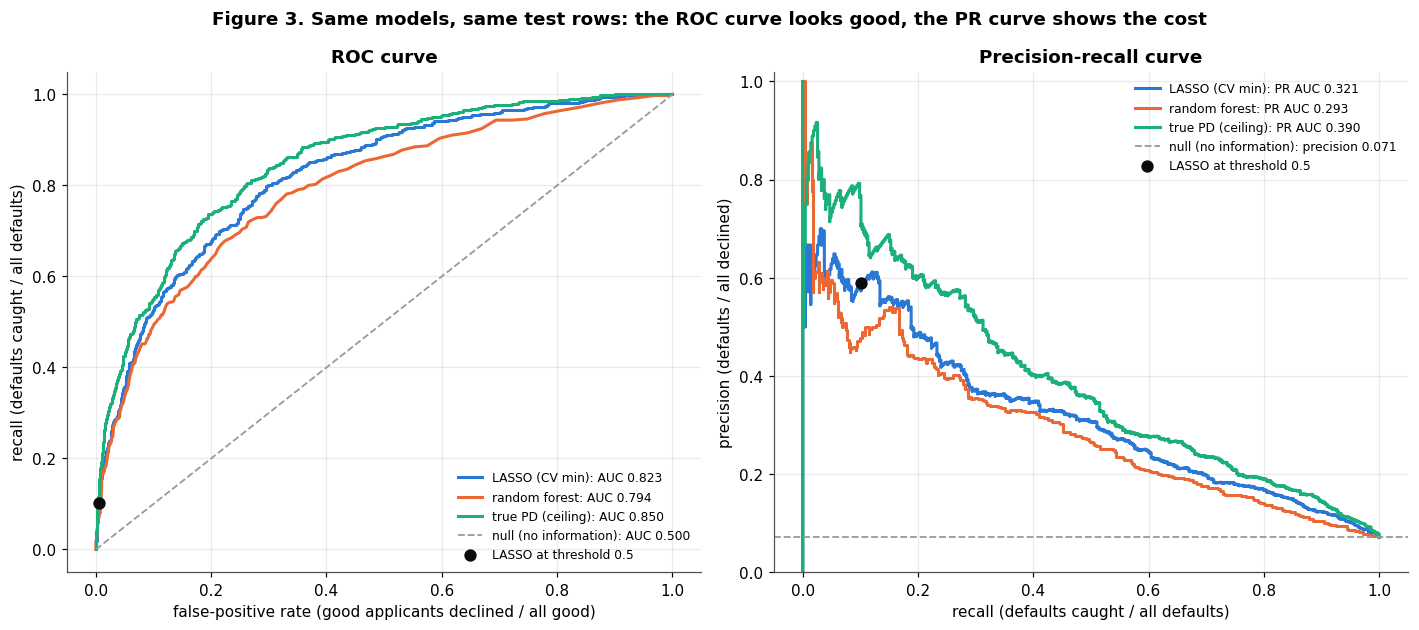

In [13]:
# ---- Figure 3: ROC and precision-recall curves on the test set ----
curve_set = [("LASSO (CV min)", p_lasso, BLUE), ("random forest", p_rf, ORANGE),
             ("true PD (ceiling)", hidden_test["_true_pd"].to_numpy(), AQUA)]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
for name, prob, colour in curve_set:
    f_, t_, _ = roc_curve(y_test, prob)
    axes[0].plot(f_, t_, color=colour, label=f"{name}: AUC {roc_auc_score(y_test, prob):.3f}")
    pr_, rc_, _ = precision_recall_curve(y_test, prob)
    axes[1].plot(rc_, pr_, color=colour, drawstyle="steps-post",
                 label=f"{name}: PR AUC {average_precision_score(y_test, prob):.3f}")
axes[0].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1.2, label="null (no information): AUC 0.500")
axes[1].axhline(y_test.mean(), color=GREY, ls="--", lw=1.2, label=f"null (no information): precision {y_test.mean():.3f}")

# The LASSO model's operating point at the default 0.5 threshold
pred05 = y_prob > 0.5
tp05, fp05 = int((pred05 & (y_test == 1)).sum()), int((pred05 & (y_test == 0)).sum())
axes[0].scatter([fp05 / n_good], [tp05 / n_def], color=INK, s=50, zorder=5, label="LASSO at threshold 0.5")
if tp05 + fp05 > 0:
    axes[1].scatter([tp05 / n_def], [tp05 / (tp05 + fp05)], color=INK, s=50, zorder=5, label="LASSO at threshold 0.5")
axes[0].set(xlabel="false-positive rate (good applicants declined / all good)", ylabel="recall (defaults caught / all defaults)",
            title="ROC curve")
axes[1].set(xlabel="recall (defaults caught / all defaults)", ylabel="precision (defaults / all declined)",
            title="Precision-recall curve", ylim=(0, 1.02))
for ax in axes:
    ax.legend(fontsize=8, loc="lower right" if ax is axes[0] else "upper right")
fig.suptitle("Figure 3. Same models, same test rows: the ROC curve looks good, the PR curve shows the cost",
             fontweight="bold")
plt.tight_layout()
plt.show()

**The scores at the default threshold.** At 0.5 the LASSO declines 73 applicants. Precision is 0.589 (43 of the 73 default), recall 0.101 (43 of 425 defaults) and F1 0.173, and it approves the other 382 defaulters. The forest matches the precision (0.590) at half the recall (0.054). ROC AUC is 0.823 (forest 0.794) and PR AUC 0.321 (forest 0.293). The ceiling is the true default probability, which knows each applicant's hidden stress. Even it reaches only ROC AUC 0.851 and PR AUC 0.390, so the LASSO already captures most of what five application fields can predict. The weak recall comes from the threshold, not the ranking: 0.5 flags only applicants judged more likely than not to default, and very few are (73 of 6,000).

**Why ROC AUC flatters at 7% prevalence.** The ROC curve plots recall against the false-positive *rate*, and that rate divides by all good applicants: 93% of the book. A false-positive rate that sounds small is therefore a large number of people. The output above shows it: catching 60% of defaults takes a false-positive rate of only 13.9%, which looks excellent on the ROC curve. In applicants it is 773 good customers declined to catch 255 defaults: precision 24.8%, or 3.0 good applicants turned away for every default caught. ROC AUC is also blind to prevalence by construction. It is the probability that a random defaulter scores above a random repayer, and the answer would be the same if defaults were 50% of the book. So it cannot reflect the base rate that makes every decline expensive. Its no-information baseline is 0.5 at any prevalence, so an AUC of 0.823 reads as "well above chance" whether defaults are 7% or 50% of the book.

**Why the precision-recall curve is the honest picture here.** Precision divides by the applicants the model actually declines, so the 93% majority enters it as false positives, at full weight. Its no-information baseline is the prevalence, 0.071, not 0.5. PR AUC 0.321 against 0.071 says the model concentrates defaults about 4.5 times better than chance, and the curve shows directly how many good applicants each extra default caught will cost. That is the trade-off the lender is pricing in Step 3.2. Even the ceiling, a model that knows each applicant's true default probability including the hidden stress, reaches only PR AUC 0.390. Default is noisy, and no model can catch most defaults without declining many good applicants.

### Step 3.2: Put a price on being wrong (30 pts)

**Cost assumptions** (shares of each application's own principal):

| Outcome | Cost | Why |
|---|---|---|
| False negative: approve, then default | **60%** | given: loss given default on an unsecured personal loan |
| False positive: decline a good applicant | **8% + 2% = 10%** | 8% interest margin forgone (given), plus a 2% reputational / relationship cost (mine, below) |
| Correct approve, correct decline | 0 | the baseline the costs are measured from |

**The 2% reputational cost.** A wrongly declined good applicant costs more than the margin on this loan.

- Many are existing customers. Some move their deposits or card to the bank that said yes, some complain, and every decline sends an adverse-action notice.
- Systematic false declines also carry fair-lending risk if they fall more heavily on some groups.
- I assume about one in four wrongly declined applicants takes other business away, and that the relationship margin lost is worth about 8% of the loan's principal. That gives 0.25 × 8% = 2%.
- This is the softest number here, so the ratio sweep below shows what happens to the threshold if it is wrong. With no reputational cost at all (8% instead of 10%), the rule threshold moves from 0.143 to 0.118.

**Costs scale with principal.** Every error is costed on that application's own loan: a missed USD 40k default costs eight times a missed USD 5k one. Both kinds of cost scale with the same principal, so for any single applicant the cost-minimising decision does not depend on loan size. Decline when p × 0.60 > (1 − p) × 0.10, that is, when **p > 0.10 / 0.70 = 1/7 ≈ 0.143**. That benchmark only holds if p is a calibrated probability, which Task 4.1 Part B checks. The empirical curve below needs no such assumption: it counts the dollars at each threshold directly.

In [14]:
LGD        = 0.60     # false negative: an approved loan that defaults loses 60% of principal
MARGIN     = 0.08     # false positive: the interest margin forgone on a good applicant we decline
REPUTATION = 0.02     # false positive: reputational / relationship cost of a wrong decline (justified above)
C_FN, C_FP = LGD, MARGIN + REPUTATION
T_BAYES    = C_FP / (C_FP + C_FN)                 # decline when p > 1/7, if p is a calibrated probability

thresholds = np.round(np.linspace(0, 1, 1001), 3)        # every threshold from 0 to 1, in steps of 0.001
principal  = X_test["loan_amount_k"].to_numpy() * 1_000  # USD; each error is costed on that application's own loan
yt = y_test.to_numpy()


def error_dollars(prob, y_true, loan, grid=thresholds):
    """For each threshold t, declining when prob > t: principal of approved defaulters (FN) and of declined repayers (FP)."""
    prob, y_true, loan = np.asarray(prob), np.asarray(y_true), np.asarray(loan)
    fn = np.array([loan[(prob <= t) & (y_true == 1)].sum() for t in grid])
    fp = np.array([loan[(prob > t) & (y_true == 0)].sum() for t in grid])
    return fn, fp


def cost_per_app(fn, fp, c_fn=C_FN, c_fp=C_FP, n=len(yt)):
    """Expected cost per application, USD."""
    return (c_fn * fn + c_fp * fp) / n


fn_usd, fp_usd = error_dollars(y_prob, yt, principal)
cost  = cost_per_app(fn_usd, fp_usd)
i_opt = int(np.argmin(cost))
t_opt = thresholds[i_opt]
i_05  = int(np.where(thresholds == 0.5)[0][0])
cost_approve_all = cost[-1]                                     # t = 1: nobody declined, the null model's cost

# The test-set minimum is picked on the test set, so its cost flatters. A threshold picked on out-of-fold
# TRAINING predictions and then scored on test shows how much of the gain survives.
oof_lasso = cross_val_predict(clone(lasso), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
fn_tr, fp_tr = error_dollars(oof_lasso, y_train, X_train["loan_amount_k"].to_numpy() * 1_000)
t_train = thresholds[int(np.argmin(cost_per_app(fn_tr, fp_tr, n=len(y_train))))]

fn_rf, fp_rf = error_dollars(p_rf, yt, principal)
cost_rf = cost_per_app(fn_rf, fp_rf)


def policy(name, t, prob=y_prob):
    dec = np.asarray(prob) > t
    c = cost_per_app(principal[(~dec) & (yt == 1)].sum(), principal[dec & (yt == 0)].sum())
    return {"policy": name, "threshold": t, "declined": int(dec.sum()), "decline rate": dec.mean(),
            "defaults caught": int((dec & (yt == 1)).sum()), "share of defaults caught": (dec & (yt == 1)).sum() / n_def,
            "good applicants declined": int((dec & (yt == 0)).sum()),
            "cost per application (USD)": c, "saving vs approve-all (USD per app)": cost_approve_all - c}


policies = pd.DataFrame([policy("approve everyone (null)", 1.0),
                         policy("threshold 0.5 (the default)", 0.5),
                         policy("rule: 1/7", T_BAYES),
                         policy("chosen on training (out-of-fold)", t_train),
                         policy("test-set minimum", t_opt),
                         policy("decline everyone", -0.001)]).set_index("policy")
display(policies)

print(f"Cost-minimising threshold on test: {t_opt:.3f}, which is {0.5 - t_opt:.3f} below the default 0.5 "
      f"(the rule says {T_BAYES:.3f}; training out-of-fold picks {t_train:.3f})")
print(f"Expected cost per application: approve all USD {cost_approve_all:,.0f} | threshold 0.5 USD {cost[i_05]:,.0f} | "
      f"minimum USD {cost[i_opt]:,.0f} ({1 - cost[i_opt] / cost_approve_all:.1%} below approve-all)")
print(f"Per 10,000 applications: saving vs approve-all USD {10_000 * (cost_approve_all - cost[i_opt]):,.0f}; "
      f"vs threshold 0.5 USD {10_000 * (cost[i_05] - cost[i_opt]):,.0f}")
print(f"Random forest's own minimum: USD {cost_rf.min():,.0f} per application at t = {thresholds[int(np.argmin(cost_rf))]:.3f}")
print("\nConfusion matrices, LASSO on the test set:")
display(pd.concat({"threshold 0.5": confusion_frame(yt, (y_prob > 0.5).astype(int)),
                   f"threshold {t_opt:.3f} (cost minimum)": confusion_frame(yt, (y_prob > t_opt).astype(int))}, axis=1))

,threshold,declined,decline rate,defaults caught,share of defaults caught,good applicants declined,cost per application (USD),saving vs approve-all (USD per app)
policy,,,,,,,,
approve everyone (null),1.0000,0,0.0000,0,0.0000,0,939.1105,0.0000
threshold 0.5 (the default),0.5000,73,0.0122,43,0.1012,30,826.7179,112.3926
rule: 1/7,0.1429,769,0.1282,222,0.5224,547,592.8223,346.2882
chosen on training (out-of-fold),0.1290,888,0.1480,238,0.5600,650,599.4773,339.6332
test-set minimum,0.1590,677,0.1128,211,0.4965,466,585.0172,354.0933
decline everyone,-0.0010,6000,1.0000,425,1.0000,5575,1730.4261,-791.3156


Cost-minimising threshold on test: 0.159, which is 0.341 below the default 0.5 (the rule says 0.143; training out-of-fold picks 0.129)
Expected cost per application: approve all USD 939 | threshold 0.5 USD 827 | minimum USD 585 (37.7% below approve-all)
Per 10,000 applications: saving vs approve-all USD 3,540,933; vs threshold 0.5 USD 2,417,007
Random forest's own minimum: USD 658 per application at t = 0.170

Confusion matrices, LASSO on the test set:


threshold 0.5          threshold 0.159 (cost minimum)         
                      approved declined                       approved declined
actual: repays            5545       30                           5109      466
actual: defaults           382       43                            214      211

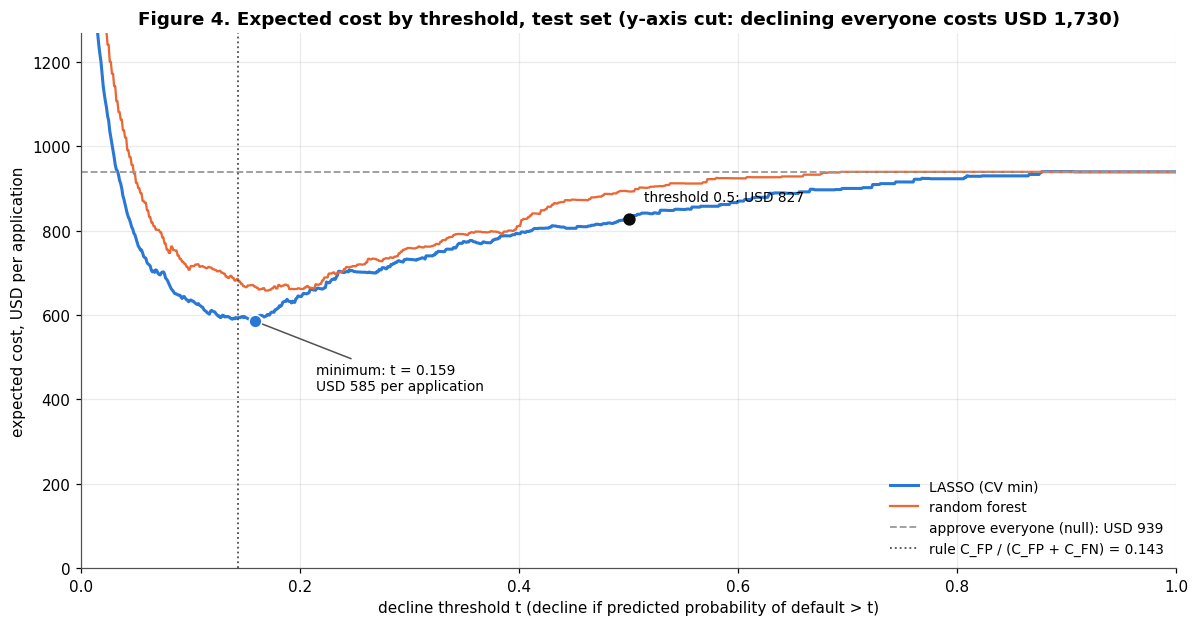

In [15]:
# ---- Figure 4: the expected-cost curve ----
fig, ax = plt.subplots(figsize=(11, 5.8))
ax.plot(thresholds, cost, color=BLUE, label="LASSO (CV min)")
ax.plot(thresholds, cost_rf, color=ORANGE, lw=1.5, label="random forest")
ax.axhline(cost_approve_all, color=GREY, ls="--", lw=1.2, label=f"approve everyone (null): USD {cost_approve_all:,.0f}")
ax.axvline(T_BAYES, color=INK_2, ls=":", lw=1.2, label=f"rule C_FP / (C_FP + C_FN) = {T_BAYES:.3f}")
ax.scatter([t_opt], [cost[i_opt]], color=BLUE, s=70, zorder=5, edgecolor="white")
ax.annotate(f"minimum: t = {t_opt:.3f}\nUSD {cost[i_opt]:,.0f} per application", (t_opt, cost[i_opt]),
            xytext=(40, -45), textcoords="offset points", fontsize=9, arrowprops=dict(arrowstyle="-", color=INK_2))
ax.scatter([0.5], [cost[i_05]], color=INK, s=50, zorder=5)
ax.annotate(f"threshold 0.5: USD {cost[i_05]:,.0f}", (0.5, cost[i_05]), xytext=(10, 12), textcoords="offset points",
            fontsize=9)
ax.set_ylim(0, 1.35 * max(cost_approve_all, cost[i_05]))
ax.set_xlim(0, 1)
ax.set_xlabel("decline threshold t (decline if predicted probability of default > t)")
ax.set_ylabel("expected cost, USD per application")
ax.set_title(f"Figure 4. Expected cost by threshold, test set (y-axis cut: declining everyone costs USD {cost[0]:,.0f})")
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()

**The cost-minimising threshold is 0.159, 0.341 below the default 0.5.** Declining every applicant with a predicted PD above 0.159 costs USD 585 per test application (policy table and Figure 4). Approving everyone, the null model, costs USD 939, and the 0.5 threshold USD 827. The minimum is 38% below approve-all, and per 10,000 applications it is USD 2.4 million cheaper than the 0.5 threshold (USD 3.5 million cheaper than approving everyone). The 0.5 threshold sits on the long climb back toward approve-all and captures under a third of the available saving (USD 112 of 354 per application). The minimum lands near the theory value of 1/7 = 0.143 because the LASSO's probabilities are calibrated, which Part B checks.

**What adopting it does to the confusion matrix** (LASSO, test set):

| | threshold 0.5 | threshold 0.159 |
|---|---|---|
| applicants declined | 73 (1.2%) | 677 (11.3%) |
| defaults caught (recall) | 43 (10%) | 211 (50%) |
| defaults approved | 382 | 214 |
| good applicants declined | 30 | 466 |
| precision | 59% | 31% |
| accuracy | 93.1% | 88.7% |

Recall goes from 10% to 50% and precision falls from 59% to 31%. **Accuracy falls to 88.7%, below the null model's 92.9%,** while expected cost falls by USD 242 per application. Each of the extra 436 good applicants declined costs 10% of a loan; each of the extra 168 defaults caught saves 60% of one. The cost-optimal model is less accurate than one that approves everybody, which is exactly why accuracy was the wrong number to sign on.

**Is the minimum real?** The 0.159 was chosen on the test set, so its USD 585 flatters slightly. A threshold chosen on out-of-fold *training* predictions, never touching the test set, is 0.129. It costs USD 599 on test, USD 14 more, and still saves 36% against approve-all. The rule's 1/7 = 0.143 uses no data at all and costs USD 593. Three thresholds between 0.129 and 0.159 land within USD 15 of each other, so the gain is real and the third decimal of the threshold is not. **The threshold I would adopt is the rule, 0.143.** It needs no tuning, it sits between the two data-chosen values, and Task 4.1 Part B checks the calibration it relies on.

,FN:FP cost ratio,optimal threshold (test),rule 1/(1+ratio),decline rate,defaults caught,good applicants declined,saving vs approve-all
0,1.0,0.484,0.5000,0.0135,49,32,0.0457
1,1.5,0.443,0.4000,0.0160,57,39,0.0808
2,2.0,0.314,0.3333,0.0333,95,105,0.1185
3,3.0,0.167,0.2500,0.1050,201,429,0.1944
4,4.0,0.159,0.2000,0.1128,211,466,0.2856
5,5.0,0.159,0.1667,0.1128,211,466,0.3405
6,6.0,0.159,0.1429,0.1128,211,466,0.3771
7,7.5,0.127,0.1176,0.1505,241,662,0.4190
8,10.0,0.092,0.0909,0.2237,284,1058,0.4760
9,12.0,0.064,0.0769,0.3192,333,1582,0.5307


Median gap between the test-set optimum and the rule, ratios 3 to 30: 0.009


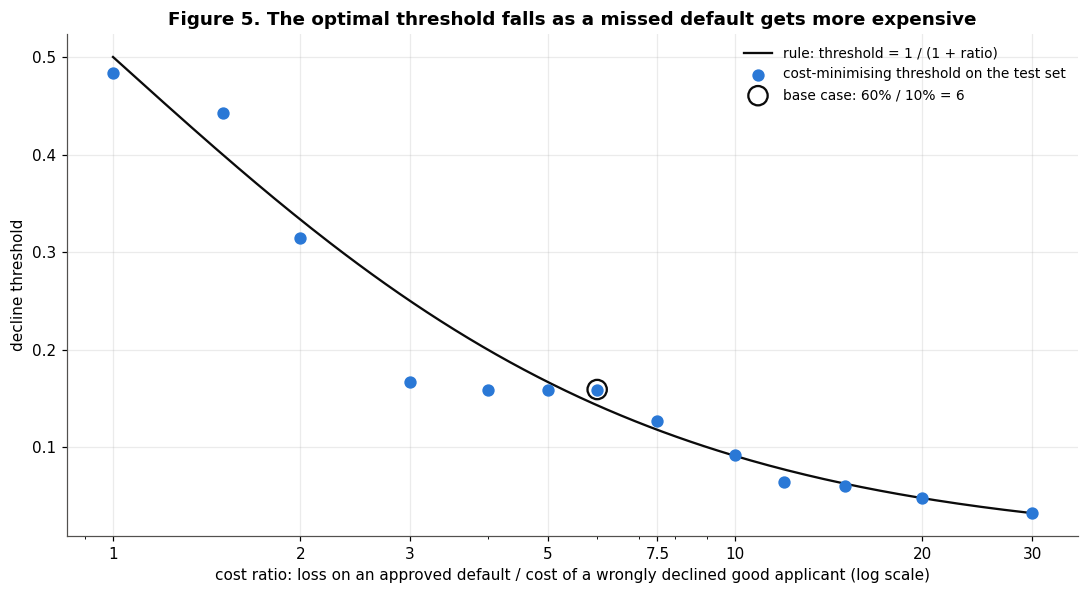

In [16]:
# ---- How the optimal threshold moves with the cost ratio ----
ratios = np.array([1, 1.5, 2, 3, 4, 5, 6, 7.5, 10, 12, 15, 20, 30])
rows = []
for r in ratios:
    c_r = cost_per_app(fn_usd, fp_usd, c_fn=r, c_fp=1.0)     # cost in units of one false-positive dollar; scale does not move the minimum
    i = int(np.argmin(c_r))
    dec = y_prob > thresholds[i]
    rows.append({"FN:FP cost ratio": r, "optimal threshold (test)": thresholds[i], "rule 1/(1+ratio)": 1 / (1 + r),
                 "decline rate": dec.mean(), "defaults caught": int((dec & (yt == 1)).sum()),
                 "good applicants declined": int((dec & (yt == 0)).sum()),
                 "saving vs approve-all": 1 - c_r[i] / c_r[-1]})
sweep = pd.DataFrame(rows)
display(sweep)
gap = (sweep["optimal threshold (test)"] - sweep["rule 1/(1+ratio)"]).abs()
print(f"Median gap between the test-set optimum and the rule, ratios 3 to 30: "
      f"{gap[sweep['FN:FP cost ratio'] >= 3].median():.3f}")

fig, ax = plt.subplots(figsize=(10, 5.5))
r_grid = np.logspace(0, np.log10(30), 200)
ax.plot(r_grid, 1 / (1 + r_grid), color=INK, lw=1.5, label="rule: threshold = 1 / (1 + ratio)")
ax.scatter(sweep["FN:FP cost ratio"], sweep["optimal threshold (test)"], color=BLUE, s=50, zorder=5,
           label="cost-minimising threshold on the test set")
ax.scatter([C_FN / C_FP], [t_opt], s=160, facecolors="none", edgecolors=INK, lw=1.5, zorder=6,
           label=f"base case: 60% / 10% = {C_FN / C_FP:.0f}")
ax.set_xscale("log")
ax.set_xticks([1, 2, 3, 5, 7.5, 10, 20, 30])
ax.set_xticklabels(["1", "2", "3", "5", "7.5", "10", "20", "30"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("cost ratio: loss on an approved default / cost of a wrongly declined good applicant (log scale)")
ax.set_ylabel("decline threshold")
ax.set_title("Figure 5. The optimal threshold falls as a missed default gets more expensive")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

**How the threshold moves.** As a missed default gets more expensive relative to a wrong decline, the cost-minimising threshold falls (table above, Figure 5). It is 0.48 at a ratio of 1, 0.16 at our 6 and 0.03 at 30. Over the same range the decline rate rises from 1% to 53%, and the saving against approve-all from 5% to 73%. The test-set optimum tracks the rule 1/(1 + ratio) closely: for ratios 3 to 30 the median gap is 0.009. Where it strays, the cost curve is flat. At ratios 3 to 6 the optimum sits on the same dip at 0.159–0.167 while the rule slides from 0.25 to 0.14. At ratios of 1 and 1.5 the model declines under 2% of applicants either way. Some business cases:

| Situation | FN cost | FP cost | Ratio | Rule threshold |
|---|---|---|---|---|
| base case | 60% | 10% | 6 | 0.143 |
| no reputational cost | 60% | 8% | 7.5 | 0.118 |
| secured loan, LGD 30% | 30% | 10% | 3 | 0.250 |
| recession, LGD 80% | 80% | 10% | 8 | 0.111 |
| reputational cost doubled to 4% | 60% | 12% | 5 | 0.167 |

**The rule for the head of risk:**

> **Decline when the model's probability of default is above *cost of wrongly declining a good applicant ÷ (that cost + loss on a loan that defaults)*.** At our numbers that is 10 ÷ 70 = **1 in 7, about 14%**, not 50%. Equivalently, the threshold is 1 ÷ (1 + the cost ratio), so it falls almost in proportion as a missed default gets dearer relative to a lost customer. Doubling the ratio from 6 to 12 takes the threshold from 14% to 8%; halving it to 3 takes it to 25%.
>
> **The rule needs calibrated probabilities**: a score of 14% must mean that 14 in 100 such applicants default. Task 4.1 Part B checks this.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: Two claims you already made, now tested (6 pts)

Both prompts were sent exactly as the brief gives them, each to a fresh model session with no access to this notebook. The prompts and replies are in the **AI Transcript** at the end. Each part below runs the model's code first, unedited, then my own check against it.

#### Part A — Does the forest actually beat the logistic model? (3 pts)

The claim being tested is Step 2.2's: that the forest does not beat the penalised logistic model (93.03% against 93.13% accuracy), read off two accuracy figures with no test.

In [17]:
# Inputs for the model's code, under the names it asked for. y_test is already the test labels.
rf_pred = rf.predict(X_test)       # random forest, hard labels at the default 0.5 cut-off (Step 2.2)
lr_pred = lasso.predict(X_test)    # penalised (CV-minimum LASSO) logistic model, same cut-off (Step 2.2)
# Note: the model's code reuses the names y and rf for its own arrays. Nothing after it needs my y or my
# forest object: every later cell uses y_test, yt, p_rf and p_lasso, which were computed above.

In [18]:
# ---- The model's code, pasted exactly as it returned it; see the AI Transcript. No line changed. ----
import numpy as np                                     # array maths
import pandas as pd                                    # labelled 2x2 table and class shares
from scipy import stats                                # exact binomial test, normal quantile

ALPHA = 0.05                                           # significance level, fixed before looking at results

y  = np.asarray(y_test).ravel()                        # true labels as a flat array (drops any pandas index)
rf = np.asarray(rf_pred).ravel()                       # forest's predicted labels -> rename to your array
lr = np.asarray(lr_pred).ravel()                       # penalised logit's predicted labels -> rename to your array

assert len(y) == len(rf) == len(lr), "arrays must cover the same test rows"                   # pairing needs one row per loan
assert np.isin(rf, y).all() and np.isin(lr, y).all(), "pass class labels, not probabilities"  # accuracy needs hard labels

rf_ok = rf == y                                        # True where the forest got the loan right
lr_ok = lr == y                                        # True where the logit got the loan right

n = len(y)                                             # number of test loans
b = int(np.sum(rf_ok & ~lr_ok))                        # forest right, logit wrong
c = int(np.sum(~rf_ok & lr_ok))                        # forest wrong, logit right
k = b + c                                              # discordant loans: the only ones that carry evidence

table = pd.crosstab(pd.Series(rf_ok, name="forest correct"),                     # rows: forest right / wrong
                    pd.Series(lr_ok, name="logit correct"))                      # columns: logit right / wrong
table = table.reindex(index=[True, False], columns=[True, False], fill_value=0)  # keep all four cells even if one is empty
print(table, "\n")                                     # off-diagonal cells are b (top-right) and c (bottom-left)

acc_rf, acc_lr = rf_ok.mean(), lr_ok.mean()            # the two accuracies
baseline = pd.Series(y).value_counts(normalize=True).max()   # accuracy of predicting the majority class for every loan

diff = (b - c) / n                                     # accuracy gap, forest minus logit (equals acc_rf - acc_lr)
se = np.sqrt(k - (b - c) ** 2 / n) / n                 # standard error of a paired difference in proportions
z = stats.norm.ppf(1 - ALPHA / 2)                      # two-sided critical value (1.96 at 5%)
lo, hi = diff - z * se, diff + z * se                  # Wald confidence interval for the gap

if k == 0:                                             # the models never disagree
    p_two = p_one = 1.0                                # so there is no evidence either way
else:                                                  # otherwise run exact McNemar
    p_two = stats.binomtest(b, k, 0.5, alternative="two-sided").pvalue   # H0: each disagreement is a coin flip
    p_one = stats.binomtest(b, k, 0.5, alternative="greater").pvalue     # H1: forest wins disagreements (only if pre-specified)

print(f"accuracy  forest {acc_rf:.4f} | logit {acc_lr:.4f} | majority-class baseline {baseline:.4f}")  # context
print(f"disagreements  forest-only right b={b} | logit-only right c={c} | n={n}")                     # the evidence
print(f"gap {100*diff:+.2f} pp, {1-ALPHA:.0%} CI [{100*lo:+.2f}, {100*hi:+.2f}] pp")                  # effect size
print(f"exact McNemar p  two-sided {p_two:.3g} | one-sided {p_one:.3g}")                              # the p-values

if p_two >= ALPHA:                                     # not significant at the pre-set level
    verdict = "is not significantly different from"    # wording for the memo
elif diff > 0:                                         # significant and forest ahead
    verdict = "is significantly higher than"           # wording for the memo
else:                                                  # significant and logit ahead
    verdict = "is significantly lower than"            # wording for the memo

print(f"\nOn the same {n:,} held-out loans, the random forest's accuracy ({acc_rf:.1%}) {verdict} "  # memo sentence, part 1
      f"the penalised logistic model's ({acc_lr:.1%}; gap {100*diff:+.2f} pp, {1-ALPHA:.0%} CI "        # part 2
      f"{100*lo:+.2f} to {100*hi:+.2f} pp; exact McNemar p = {p_two:.2g}), against {baseline:.1%} "     # part 3
      f"for simply predicting the majority class.")                                                    # part 4

logit correct   True   False
forest correct              
True             5562     20
False              26    392 

accuracy  forest 0.9303 | logit 0.9313 | majority-class baseline 0.9292
disagreements  forest-only right b=20 | logit-only right c=26 | n=6000
gap -0.10 pp, 95% CI [-0.32, +0.12] pp
exact McNemar p  two-sided 0.461 | one-sided 0.849

On the same 6,000 held-out loans, the random forest's accuracy (93.0%) is not significantly different from the penalised logistic model's (93.1%; gap -0.10 pp, 95% CI -0.32 to +0.12 pp; exact McNemar p = 0.46), against 92.9% for simply predicting the majority class.


In [19]:
# ---- Mine, not the model's: the 2x2 agreement table, McNemar both ways, and what ignoring the pairing would give ----
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.proportion import proportions_ztest

f_ok = np.asarray(rf_pred) == yt          # forest right
l_ok = np.asarray(lr_pred) == yt          # logistic right
agree = pd.DataFrame([[int(np.sum(f_ok & l_ok)), int(np.sum(f_ok & ~l_ok))],
                      [int(np.sum(~f_ok & l_ok)), int(np.sum(~f_ok & ~l_ok))]],
                     index=["forest right", "forest wrong"], columns=["logistic right", "logistic wrong"])
display(agree)

b_f, c_l = int(agree.iloc[0, 1]), int(agree.iloc[1, 0])
n_disc = b_f + c_l
p_exact = stats.binomtest(b_f, n_disc, 0.5).pvalue if n_disc > 0 else 1.0
mc_exact = mcnemar(agree.to_numpy(), exact=True)
mc_chi2  = mcnemar(agree.to_numpy(), exact=False, correction=True)
use_exact = n_disc < 25
_, p_indep = proportions_ztest([int(f_ok.sum()), int(l_ok.sum())], [len(yt), len(yt)])

print(f"Accuracy: forest {f_ok.mean():.4f}, logistic {l_ok.mean():.4f}, null {null_acc:.4f}")
print(f"Concordant rows (carry no evidence): both right {agree.iloc[0, 0]:,}, both wrong {agree.iloc[1, 1]:,}")
print(f"b = forest right, logistic wrong = {b_f}")
print(f"c = forest wrong, logistic right = {c_l}")
print(f"b + c = {n_disc} discordant rows")
print(f"Exact binomial, b ~ Bin(b + c, 0.5): p = {p_exact:.4f}   (statsmodels exact McNemar: {mc_exact.pvalue:.4f})")
print(f"Continuity-corrected chi-square: statistic {mc_chi2.statistic:.3f}, p = {mc_chi2.pvalue:.4f}")
print(f"Test used: {'exact binomial (b + c < 25)' if use_exact else 'continuity-corrected chi-square (b + c >= 25)'}; "
      f"p = {p_exact if use_exact else mc_chi2.pvalue:.4f}")
print(f"For contrast, an independent two-proportion z-test that ignores the pairing: p = {p_indep:.4f}")

,logistic right,logistic wrong
forest right,5562,20
forest wrong,26,392


Accuracy: forest 0.9303, logistic 0.9313, null 0.9292
Concordant rows (carry no evidence): both right 5,562, both wrong 392
b = forest right, logistic wrong = 20
c = forest wrong, logistic right = 26
b + c = 46 discordant rows
Exact binomial, b ~ Bin(b + c, 0.5): p = 0.4614   (statsmodels exact McNemar: 0.4614)
Continuity-corrected chi-square: statistic 0.543, p = 0.4610
Test used: continuity-corrected chi-square (b + c >= 25); p = 0.4610
For contrast, an independent two-proportion z-test that ignores the pairing: p = 0.8291


**What the model did with the gap.** The prompt left out the two accuracies and never said whether the models were scored on the same rows. The model did not fall into the usual trap. It said a p-value cannot come from two accuracies alone, read "scored on my test set" as the same rows, chose the exact McNemar test, which is the right one, and explained why an independent-samples test would be wrong. Two guesses remain in the reply, and my outputs catch both:

- **It guessed the forest won.** Its advice against one-sided tests opens with "You've already seen that the forest scored higher." It did not: the forest scored 0.10 points *lower*, 93.03% against 93.13%. Its code assumes no direction, so its numbers are right; only the advice wrapped around them is wrong.
- **It guessed the accuracies meant something.** Its example used 0.91 against 0.93. Its own caveat about the majority-class baseline is the line that matters here: the baseline is 92.92%, so both models are within 0.21 points of a model that learned nothing.

Its code ran unchanged. It printed b = 20, c = 26, an exact two-sided p of 0.461, and a 95% interval for the accuracy gap of −0.32 to +0.12 points.

**The test, done properly.** My own cell rebuilds the 2×2 agreement table (above). 5,562 test rows are right under both models and 392 wrong under both. Those 5,954 concordant rows say nothing about which model is better. The evidence is in the 46 rows where the models disagree:

- **b = 20**: forest right, logistic wrong.
- **c = 26**: forest wrong, logistic right.
- **b + c = 46.**

Under the null hypothesis each discordant row falls either way with probability one half, so b ~ Binomial(46, 0.5). With 46 discordant rows, above the usual cut-off of 25, I report the **continuity-corrected chi-square: statistic 0.54, p = 0.461**. The exact binomial gives the same p = 0.461, so the choice of test does not matter here. A two-proportion z-test that ignores the pairing gives p = 0.83. It treats the 12,000 predictions as independent, so the 5,954 rows that cancel out swamp the 46 that carry evidence.

**Does the Step 2.2 verdict survive? Yes, and it gets sharper.** Step 2.2 said the forest does not win. McNemar says the two models are indistinguishable on accuracy (p = 0.46): 46 disagreements split 20 to 26 are what a coin would produce. So the expensive model cannot be shown to beat the cheap one. Its lower ROC AUC (−0.029) and PR AUC (−0.028), not tested here, point the same way. That is the finding the lender needs: there is no reason to pay for the forest, and the cheap model is the one it can explain to a regulator.

**The limitation.** McNemar here asks whether the two models make different *numbers of errors* at the 0.5 cut-off, which Phase 3 showed is not what the lender pays for. The comparison that matches the decision is paired on the same test rows: the difference in expected cost (or in PR AUC) between the two models, each at its own cost-minimising threshold, with a confidence interval from a bootstrap that resamples test rows and scores both models on each resample, so the pairing is kept.

#### Part B — Is your Phase 3 threshold valid? (3 pts)

In [20]:
# Inputs for the model's code: y_test (test labels) and y_prob (the LASSO's test-set default probabilities, Phase 3).
y_prob = p_lasso
# Note: the model's code reuses some of my names for its own objects (y, logit, p_platt, p_iso, policies, C_FN,
# C_FP, EPS). Its C_FN, C_FP and EPS are set to the same values as mine, and my cells after it redefine the rest.

n=6,000  defaults=425  prevalence=7.08%  mean predicted PD=7.04%

Raw model: 10 bins
         PD range       n  defaults  mean PD  observed   95% Jeffreys CI
  0.0000-  0.0065     600         2   0.0037    0.0033   [0.0007, 0.0107]
  0.0065-  0.0116     600         6   0.0090    0.0100   [0.0042, 0.0205]
  0.0116-  0.0180     600        10   0.0146    0.0167   [0.0086, 0.0294]
  0.0180-  0.0252     600        11   0.0213    0.0183   [0.0098, 0.0315]
  0.0252-  0.0345     600        18   0.0297    0.0300   [0.0185, 0.0460]
  0.0345-  0.0487     600        18   0.0413    0.0300   [0.0185, 0.0460]
  0.0487-  0.0685     600        39   0.0583    0.0650   [0.0473, 0.0868]
  0.0685-  0.1013     600        52   0.0834    0.0867   [0.0661, 0.1112]
  0.1013-  0.1744     600        76   0.1310    0.1267   [0.1019, 0.1551]
  0.1744-  0.9068     600       193   0.3117    0.3217   [0.2852, 0.3598]

Platt (cross-fit): 10 bins
         PD range       n  defaults  mean PD  observed   95% Jeffreys CI
 

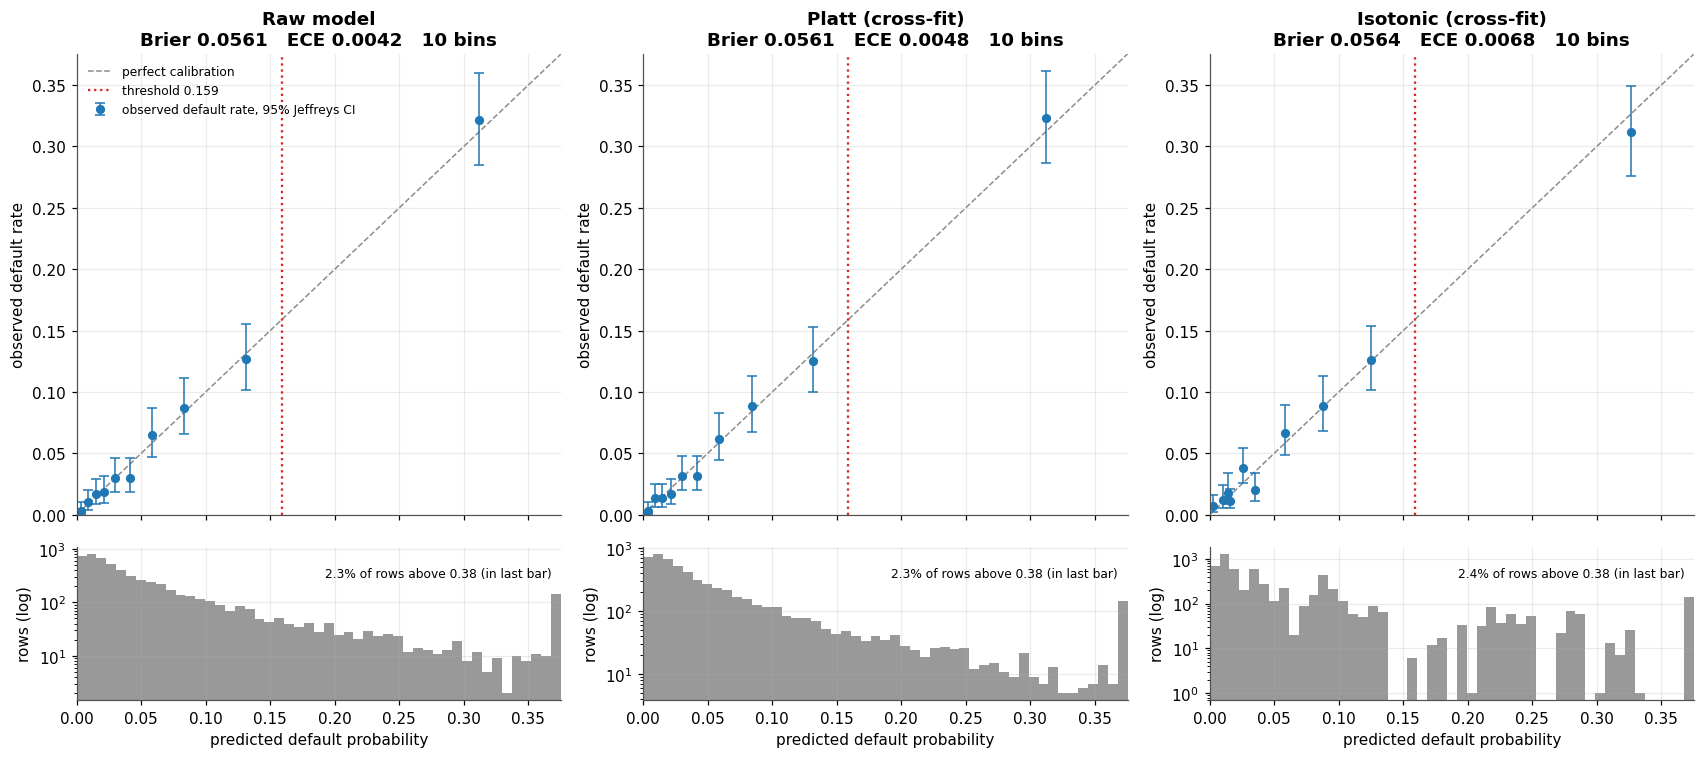


                             Raw model     Platt (cross-fit)  Isotonic (cross-fit)
Brier                         0.056056              0.056067              0.056407
Brier skill                    0.14828               0.14812               0.14296
 reliability                3.1581e-05             3.475e-05            7.2572e-05
 resolution                  0.0083601             0.0084251             0.0079347
 uncertainty                  0.065816              0.065816              0.065816
 within-bin                 -0.0014309            -0.0013584            -0.0015467
ECE                          0.0042285             0.0047845             0.0067636
O/E defaults                    1.0062               0.99966               0.99853
Cox slope                      0.99519               0.99852               0.87462
Cox intercept               -0.0021231            -0.0034552              -0.25443
Spiegelhalter p                0.76783                 0.904               0.57233
log

In [21]:
# ---- The model's code, section 1 of 2 (calibration, recalibration), pasted exactly as it returned it; see the AI ----
# ---- Transcript. Three lines changed, each marked CHANGED: the constants its own comments said to replace.     ----
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta, norm          # scipy is installed with scikit-learn
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold

# ------------------------------------------------------------------ config
N_BINS    = 10     # equal-frequency bins; use 15-20 if the test set is large
MIN_COUNT = 100    # smallest bin allowed after merging
C_FN      = 0.60   # CHANGED (was 10.0, marked REPLACE): my Phase 3 loss on an approved default, 60% of principal
C_FP      = 0.10   # CHANGED (was 1.0, marked REPLACE): my Phase 3 cost of a wrong decline, 8% margin + 2% reputational
T_PHASE3  = t_opt  # CHANGED (was 0.09, marked REPLACE): my Phase 3 cost-minimising threshold
EPS = 1e-6

# ------------------------------------------------------------------ inputs
y = np.asarray(y_test).astype(int).ravel()
p_raw = np.asarray(y_prob, dtype=float)
p_raw = (p_raw[:, 1] if p_raw.ndim == 2 else p_raw).ravel()   # also accepts predict_proba output
assert y.shape == p_raw.shape and set(np.unique(y)) <= {0, 1}
print(f"n={len(y):,}  defaults={y.sum():,}  prevalence={y.mean():.2%}  "
      f"mean predicted PD={p_raw.mean():.2%}")

# ------------------------------------------------------------------ binning
def adaptive_bins(p, n_bins=N_BINS, min_count=MIN_COUNT):
    """Equal-frequency bins, then merge neighbours until each has >= min_count rows.
    With fixed-width bins at 7% prevalence, the bins above 0.5 hold only a few rows.
    Their 0% or 100% observed rates look like miscalibration but are just noise."""
    inner = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))[1:-1]
    raw_id = np.searchsorted(inner, p, side="right")
    counts = np.bincount(raw_id, minlength=len(inner) + 1)
    new_id, b, run = np.zeros_like(counts), 0, 0
    for k, c in enumerate(counts):
        new_id[k], run = b, run + c
        if run >= min_count:
            b, run = b + 1, 0
    if run > 0 and b > 0:                      # top bin too small -> fold into the one below
        new_id[new_id == b] = b - 1
    return new_id[raw_id]

def bin_table(y, p, bin_id, level=0.95):
    K = bin_id.max() + 1
    n = np.bincount(bin_id, minlength=K)
    d = np.bincount(bin_id, weights=y, minlength=K)
    pred = np.bincount(bin_id, weights=p, minlength=K) / n
    obs, a = d / n, (1 - level) / 2
    # Jeffreys interval, the standard interval in PD back-testing
    lo = np.where(d > 0, beta.ppf(a, d + 0.5, n - d + 0.5), 0.0)
    hi = np.where(d < n, beta.ppf(1 - a, d + 0.5, n - d + 0.5), 1.0)
    return dict(n=n, d=d, pred=pred, obs=obs, lo=lo, hi=hi)

def print_bins(y, p, label):
    b = adaptive_bins(p); t = bin_table(y, p, b)
    print(f"\n{label}: {len(t['n'])} bins")
    print(f"{'PD range':>17}{'n':>8}{'defaults':>10}{'mean PD':>9}{'observed':>10}   95% Jeffreys CI")
    for k in range(len(t["n"])):
        pk = p[b == k]
        flag = "" if t["lo"][k] <= t["pred"][k] <= t["hi"][k] else "   <-- CI excludes mean PD"
        print(f"{pk.min():8.4f}-{pk.max():8.4f}{t['n'][k]:8d}{int(t['d'][k]):10d}"
              f"{t['pred'][k]:9.4f}{t['obs'][k]:10.4f}   [{t['lo'][k]:.4f}, {t['hi'][k]:.4f}]{flag}")

# ------------------------------------------------------------------ metrics
def logit(p):
    p = np.clip(p, EPS, 1 - EPS)
    return np.log(p / (1 - p))

def calibration_report(y, p):
    b = adaptive_bins(p); t = bin_table(y, p, b)
    N, base = len(y), y.mean()
    rel = np.sum(t["n"] * (t["pred"] - t["obs"]) ** 2) / N      # reliability: lower is better
    res = np.sum(t["n"] * (t["obs"] - base) ** 2) / N           # resolution: higher is better
    unc = base * (1 - base)                                     # uncertainty: fixed by prevalence
    dp, dy = p - t["pred"][b], y - t["obs"][b]
    within = (np.sum(dp ** 2) - 2 * np.sum(dp * dy)) / N        # nonzero because PDs vary within bins
    bs = np.mean((p - y) ** 2)
    assert np.isclose(bs, rel - res + unc + within)             # decomposition is exact
    cox = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p)[:, None], y)
    z = np.sum((y - p) * (1 - 2 * p)) / np.sqrt(np.sum((1 - 2 * p) ** 2 * p * (1 - p)))
    return {"Brier": bs, "Brier skill": 1 - bs / unc,
            " reliability": rel, " resolution": res, " uncertainty": unc, " within-bin": within,
            "ECE": np.sum(t["n"] * np.abs(t["pred"] - t["obs"])) / N,
            "O/E defaults": y.sum() / p.sum(),
            "Cox slope": cox.coef_[0, 0], "Cox intercept": cox.intercept_[0],
            "Spiegelhalter p": 2 * norm.sf(abs(z)),
            "log loss": log_loss(y, np.clip(p, EPS, 1 - EPS)),
            "AUC": roc_auc_score(y, p)}

# ------------------------------------------------------------------ recalibration (cross-fitted)
def crossfit_calibrators(y, p, n_splits=5, seed=42):
    """Out-of-fold Platt and isotonic PDs. Each row is calibrated by a map fitted on
    the other folds, so the test set never grades its own fit."""
    z = logit(p)[:, None]          # Platt on logit(p): "do nothing" (slope 1, intercept 0) is in the family
    platt, iso = np.empty_like(p), np.empty_like(p)
    for tr, te in StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(z, y):
        platt[te] = (LogisticRegression(C=1e6, max_iter=1000)
                     .fit(z[tr], y[tr]).predict_proba(z[te])[:, 1])
        iso[te] = (IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip")
                   .fit(p[tr], y[tr]).predict(p[te]))
    return platt, iso

def paired_bootstrap(y, p_ref, p_new, B=2000, seed=0):
    rng = np.random.default_rng(seed)
    d = (p_new - y) ** 2 - (p_ref - y) ** 2                     # per-row change in Brier
    boots = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(B)])
    return d.mean(), *np.percentile(boots, [2.5, 97.5])

# ------------------------------------------------------------------ reliability diagram
def plot_reliability(y, preds, threshold=None, log_axes=False):
    tables = {k: bin_table(y, p, adaptive_bins(p)) for k, p in preds.items()}
    # zoom to where predictions actually are, not an empty [0, 1] square
    top = min(1.0, 1.15 * max(max(t["pred"].max(), t["obs"].max()) for t in tables.values()))
    bottom = max(1e-4, 0.5 * min(t["pred"].min() for t in tables.values())) if log_axes else 0.0
    fig, axes = plt.subplots(2, len(preds), figsize=(5.2 * len(preds), 7), sharex="col",
                             gridspec_kw={"height_ratios": [3, 1]}, squeeze=False)
    for j, (name, p) in enumerate(preds.items()):
        t, ax, axh = tables[name], axes[0, j], axes[1, j]
        x = np.maximum(t["pred"], bottom)
        o = np.maximum(t["obs"], bottom)       # on log axes, zero-default bins sit on the floor
        err = [np.clip(o - np.maximum(t["lo"], bottom), 0, None), np.clip(t["hi"] - o, 0, None)]
        ax.plot([bottom, top], [bottom, top], ls="--", lw=1, color="0.55", label="perfect calibration")
        ax.errorbar(x, o, yerr=err, fmt="o", ms=5, color="C0", elinewidth=1, capsize=3,
                    label="observed default rate, 95% Jeffreys CI")
        if threshold is not None:
            ax.axvline(threshold, color="C3", ls=":", lw=1.5, label=f"threshold {threshold:.3f}")
        ece = np.sum(t["n"] * np.abs(t["pred"] - t["obs"])) / len(y)
        ax.set_title(f"{name}\nBrier {np.mean((p - y) ** 2):.4f}   ECE {ece:.4f}   {len(t['n'])} bins")
        ax.set_ylabel("observed default rate")
        hb = np.geomspace(bottom, top, 50) if log_axes else np.linspace(0, top, 50)
        axh.hist(np.clip(p, hb[0], hb[-1]), bins=hb, color="0.6")
        axh.set_yscale("log")                  # log counts so the thin high-PD tail stays visible
        axh.set_xlabel("predicted default probability"); axh.set_ylabel("rows (log)")
        if np.mean(p > top) > 0:
            axh.text(0.98, 0.8, f"{np.mean(p > top):.1%} of rows above {top:.2f} (in last bar)",
                     transform=axh.transAxes, ha="right", fontsize=8)
        if log_axes:
            ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlim(bottom, top); ax.set_ylim(bottom, top)
    axes[0, 0].legend(loc="upper left", fontsize=8)
    fig.tight_layout(); plt.show()

# ------------------------------------------------------------------ run
p_platt, p_iso = crossfit_calibrators(y, p_raw)
preds = {"Raw model": p_raw, "Platt (cross-fit)": p_platt, "Isotonic (cross-fit)": p_iso}

for name, p in preds.items():
    print_bins(y, p, name)
plot_reliability(y, preds, threshold=T_PHASE3)      # log_axes=True spreads out the crowded low-PD bins

reports = {name: calibration_report(y, p) for name, p in preds.items()}
print(f"\n{'':<16}" + "".join(f"{n:>22}" for n in reports))
for metric in reports["Raw model"]:
    print(f"{metric:<16}" + "".join(f"{r[metric]:>22.5g}" for r in reports.values()))

print("\nBrier change vs raw (negative = better), 95% paired bootstrap CI:")
for name in ["Platt (cross-fit)", "Isotonic (cross-fit)"]:
    m, lo, hi = paired_bootstrap(y, p_raw, preds[name])
    verdict = "IMPROVES" if hi < 0 else "WORSENS" if lo > 0 else "no detectable change"
    print(f"  {name:<22}{m:+.6f}  [{lo:+.6f}, {hi:+.6f}]  -> {verdict}")

In [22]:
# ---- The model's code, section 2 of 2 (threshold check), pasted exactly as it returned it. No line changed. ----
t_bayes = C_FP / (C_FP + C_FN)   # break-even PD: the optimal cutoff only if PDs are calibrated

def realized_cost(y, p, t):      # cost per applicant, rejecting when p >= t
    reject = p >= t
    return (C_FN * np.sum((y == 1) & ~reject) + C_FP * np.sum((y == 0) & reject)) / len(y)

def marginal_default_rate(y, p, t, share=0.10):
    """Observed default rate among the `share` of applicants scored closest to t:
    the people whose decision the threshold actually changes."""
    order = np.argsort(p)
    c, h = np.searchsorted(p[order], t), max(25, int(share * len(p) / 2))
    idx = order[max(0, c - h): c + h]
    n, d = len(idx), y[idx].sum()
    return p[idx].mean(), d / n, *beta.ppf([0.025, 0.975], d + 0.5, n - d + 0.5)

m, r, lo, hi = marginal_default_rate(y, p_raw, T_PHASE3)
print(f"Break-even PD from costs: {t_bayes:.4f}   Phase 3 threshold: {T_PHASE3:.4f}")
print(f"Applicants near the threshold: mean predicted {m:.4f}, observed {r:.4f} [{lo:.4f}, {hi:.4f}]")
if lo > t_bayes:
    print("-> marginal applicants default above break-even: cutoff too HIGH (approving loss-makers)")
elif hi < t_bayes:
    print("-> marginal applicants default below break-even: cutoff too LOW (rejecting profitable borrowers)")
else:
    print("-> marginal default rate consistent with break-even at this sample size")

grid = np.unique(np.quantile(p_raw, np.linspace(0, 1, 1001)))
best = grid[np.argmin([realized_cost(y, p_raw, t) for t in grid])]
policies = [("raw @ Phase 3 threshold", p_raw, T_PHASE3),
            ("raw @ break-even PD", p_raw, t_bayes),
            ("Platt @ break-even PD", p_platt, t_bayes),
            ("isotonic @ break-even PD", p_iso, t_bayes),
            ("raw @ in-sample best*", p_raw, best)]
print(f"\n{'policy':<27}{'cutoff':>8}{'reject %':>10}{'cost/applicant':>16}")
for lab, p, t in policies:
    print(f"{lab:<27}{t:8.4f}{np.mean(p >= t):10.1%}{realized_cost(y, p, t):16.4f}")
print("* tuned on this same data: an optimistic ceiling, not a deployable number")

Break-even PD from costs: 0.1429   Phase 3 threshold: 0.1590
Applicants near the threshold: mean predicted 0.1640, observed 0.1817 [0.1524, 0.2140]
-> marginal applicants default above break-even: cutoff too HIGH (approving loss-makers)

policy                       cutoff  reject %  cost/applicant
raw @ Phase 3 threshold      0.1590     11.3%          0.0292
raw @ break-even PD          0.1429     12.8%          0.0294
Platt @ break-even PD        0.1429     13.0%          0.0295
isotonic @ break-even PD     0.1429     11.8%          0.0291
raw @ in-sample best*        0.1533     11.9%          0.0291
* tuned on this same data: an optimistic ceiling, not a deployable number


,Brier,reliability (lower better),resolution (higher better),uncertainty,REL - RES + UNC,ECE (decile bins),mean predicted PD,observed default rate,top decile: predicted,top decile: observed,ROC AUC
LASSO raw (Phase 3),0.0561,3.1581e-05,0.0084,0.0658,0.0575,0.0042,0.0704,0.0708,0.3117,0.3217,0.8232
LASSO + Platt,0.0561,2.8190e-05,0.0084,0.0658,0.0575,0.0041,0.0705,0.0708,0.3136,0.3217,0.8232
LASSO + isotonic,0.0560,1.1086e-04,0.0085,0.0658,0.0574,0.0082,0.0704,0.0708,0.3222,0.3267,0.8209
random forest raw,0.0577,2.5009e-04,0.0073,0.0658,0.0588,0.0112,0.0780,0.0708,0.3134,0.3083,0.7938


LASSO raw      calibration intercept -0.003, slope 0.995   (perfect: 0 and 1)
LASSO + Platt  calibration intercept -0.018, slope 0.988   (perfect: 0 and 1)

LASSO raw, decile bins on the test set:


,n,defaults,mean_pred,obs_rate,ci_lo,ci_hi
bin,,,,,,
0,600,2,0.0037,0.0033,0.0009,0.0121
1,600,6,0.0090,0.0100,0.0046,0.0216
2,600,10,0.0146,0.0167,0.0091,0.0304
3,600,11,0.0213,0.0183,0.0103,0.0325
4,600,18,0.0297,0.0300,0.0191,0.0469
5,600,18,0.0413,0.0300,0.0191,0.0469
6,600,39,0.0583,0.0650,0.0479,0.0876
7,600,52,0.0834,0.0867,0.0667,0.1119
8,600,76,0.1310,0.1267,0.1024,0.1557


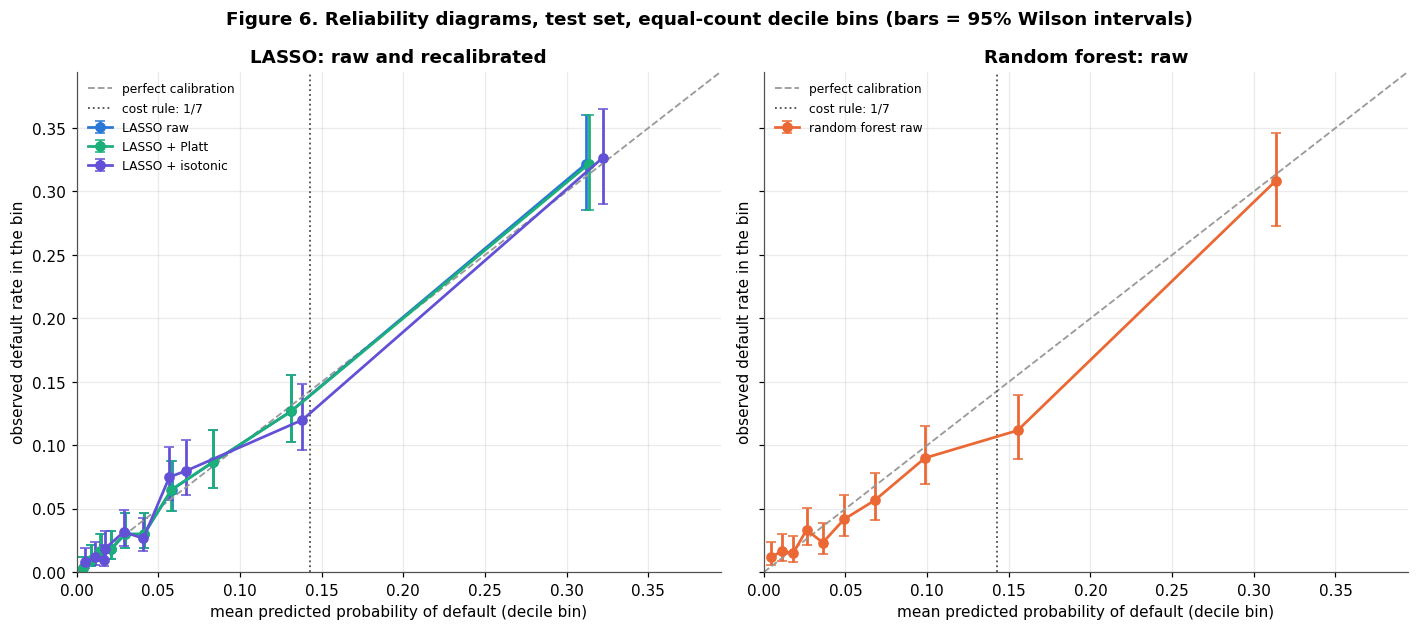

In [23]:
# ---- Mine, not the model's: calibrators fitted on TRAINING out-of-fold predictions, judged on test ----
from statsmodels.stats.proportion import proportion_confint

EPS = 1e-6
platt_cal = LogisticRegression(C=1e6, max_iter=1000).fit(logit(np.clip(oof_lasso, EPS, 1 - EPS)).reshape(-1, 1), y_train)
iso_cal   = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(oof_lasso, y_train)
p_platt = platt_cal.predict_proba(logit(np.clip(p_lasso, EPS, 1 - EPS)).reshape(-1, 1))[:, 1]
p_iso   = iso_cal.predict(p_lasso)


def reliability_bins(y_true, p, n_bins=10):
    """Equal-COUNT bins (deciles of predicted PD), so the sparse high-PD end still gets ~600 rows per bin."""
    d = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(p)})
    d["bin"] = pd.qcut(d["p"].rank(method="first"), n_bins, labels=False)
    g = d.groupby("bin").agg(n=("y", "size"), defaults=("y", "sum"), mean_pred=("p", "mean"), obs_rate=("y", "mean"))
    g["ci_lo"], g["ci_hi"] = proportion_confint(g["defaults"], g["n"], alpha=0.05, method="wilson")
    return g


def calibration_report(y_true, p, n_bins=10):
    y_true, p = np.asarray(y_true), np.asarray(p)
    g = reliability_bins(y_true, p, n_bins)
    n, base = g["n"].sum(), y_true.mean()
    rel = (g["n"] * (g["mean_pred"] - g["obs_rate"]) ** 2).sum() / n      # Murphy decomposition on the decile bins
    res = (g["n"] * (g["obs_rate"] - base) ** 2).sum() / n
    return {"Brier": brier_score_loss(y_true, p), "reliability (lower better)": rel,
            "resolution (higher better)": res, "uncertainty": base * (1 - base),
            "REL - RES + UNC": rel - res + base * (1 - base),
            "ECE (decile bins)": (g["n"] * (g["mean_pred"] - g["obs_rate"]).abs()).sum() / n,
            "mean predicted PD": p.mean(), "observed default rate": base,
            "top decile: predicted": g["mean_pred"].iloc[-1], "top decile: observed": g["obs_rate"].iloc[-1],
            "ROC AUC": roc_auc_score(y_true, p)}


cal_sets = {"LASSO raw (Phase 3)": p_lasso, "LASSO + Platt": p_platt, "LASSO + isotonic": p_iso,
            "random forest raw": p_rf}
cal_table = pd.DataFrame({k: calibration_report(yt, v) for k, v in cal_sets.items()}).T
display(cal_table)

for name, p in [("LASSO raw", p_lasso), ("LASSO + Platt", p_platt)]:
    recal = sm.Logit(yt, sm.add_constant(logit(np.clip(p, EPS, 1 - EPS)))).fit(disp=0)
    print(f"{name:14s} calibration intercept {recal.params[0]:+.3f}, slope {recal.params[1]:.3f}   (perfect: 0 and 1)")
print("\nLASSO raw, decile bins on the test set:")
display(reliability_bins(yt, p_lasso))

# Figure 6: reliability diagrams with 95% Wilson intervals
panels = [("LASSO: raw and recalibrated", [("LASSO raw", p_lasso, BLUE), ("LASSO + Platt", p_platt, AQUA),
                                           ("LASSO + isotonic", p_iso, VIOLET)]),
          ("Random forest: raw", [("random forest raw", p_rf, ORANGE)])]
lim = 1.08 * max(reliability_bins(yt, p)[["mean_pred", "ci_hi"]].to_numpy().max() for p in [p_lasso, p_platt, p_iso, p_rf])
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8), sharex=True, sharey=True)
for ax, (title, series) in zip(axes, panels):
    for name, p, colour in series:
        g = reliability_bins(yt, p)
        ax.errorbar(g["mean_pred"], g["obs_rate"], yerr=[g["obs_rate"] - g["ci_lo"], g["ci_hi"] - g["obs_rate"]],
                    color=colour, marker="o", ms=6, lw=1.8, capsize=3, label=name)
    ax.plot([0, lim], [0, lim], color=GREY, ls="--", lw=1.2, label="perfect calibration")
    ax.axvline(T_BAYES, color=INK_2, ls=":", lw=1.2, label="cost rule: 1/7")
    ax.set(xlim=(0, lim), ylim=(0, lim), title=title, xlabel="mean predicted probability of default (decile bin)",
           ylabel="observed default rate in the bin")
    ax.legend(fontsize=8, loc="upper left")
fig.suptitle("Figure 6. Reliability diagrams, test set, equal-count decile bins (bars = 95% Wilson intervals)",
             fontweight="bold")
plt.tight_layout()
plt.show()

In [24]:
# ---- Recompute the Phase 3 threshold on calibrated probabilities, and test the 1/7 rule on each ----
rows = []
for name, p in [("LASSO raw (Phase 3)", p_lasso), ("LASSO + Platt", p_platt), ("LASSO + isotonic", p_iso),
                ("random forest raw", p_rf)]:
    p = np.asarray(p)
    fn_c, fp_c = error_dollars(p, yt, principal)
    c_c = cost_per_app(fn_c, fp_c)
    i = int(np.argmin(c_c))
    rule = p > T_BAYES
    cost_rule = cost_per_app(principal[(~rule) & (yt == 1)].sum(), principal[rule & (yt == 0)].sum())
    rows.append({"probabilities": name, "cost-minimising threshold": thresholds[i], "minimum cost (USD/app)": c_c[i],
                 "declined at minimum": int((p > thresholds[i]).sum()),
                 "rule p > 1/7: cost (USD/app)": cost_rule, "rule: excess over minimum": cost_rule - c_c[i],
                 "rule: declined": int(rule.sum())})
display(pd.DataFrame(rows).set_index("probabilities"))

,cost-minimising threshold,minimum cost (USD/app),declined at minimum,rule p > 1/7: cost (USD/app),rule: excess over minimum,rule: declined
probabilities,,,,,,
LASSO raw (Phase 3),0.159,585.0172,677,592.8223,7.8051,769
LASSO + Platt,0.159,586.0153,678,593.3971,7.3818,770
LASSO + isotonic,0.154,590.7047,719,591.1144,0.4097,796
random forest raw,0.170,657.9612,764,685.3247,27.3635,985


**What the model's code showed.** The prompt left out the model, the costs and the threshold, and asked for a verdict on a reliability diagram the model could not see. The reply said so and gave no verdict without the numbers. Its code used placeholder costs (10 : 1) and a placeholder threshold (0.09), marked for replacement. With my values in, it ran without errors (its figure and tables are above). On the test set it found:

- **The raw LASSO probabilities are well calibrated.** Mean predicted PD is 7.04% against 7.08% observed (O/E 1.006). The Cox slope is 0.995 and the intercept −0.002 (perfect: 1 and 0). The Spiegelhalter test gives p = 0.77, and in all ten equal-count bins the 95% interval covers the mean prediction.
- **Neither recalibration helps.** Cross-fitted on the test set, Platt changes the Brier score by +0.00001 and isotonic by +0.00035, both with bootstrap intervals spanning zero. Isotonic makes calibration slightly *worse* (Cox slope 0.87, two bins flagged): with 425 defaults it overfits.
- **Its threshold check calls 0.159 too high.** Applicants scored around 0.159 default at 18.2% (95% interval 15.2% to 21.4%), above break-even at 14.3%. The window is centred on 0.159 by rank, though, and its mean prediction is 0.164, so it mostly covers applicants above the cut-off, who are declined either way. On its own cost measure, which counts errors rather than dollars, 0.159 and 0.143 are within 0.0002 per applicant.

**The calibration check, done on held-out data.** My own check fits the calibrators on out-of-fold *training* predictions and scores them on the test set, so no test row grades its own calibrator. The reply cross-fitted on the test set itself, which works as a diagnostic but leaves no untouched rows. The two agree:

- **Calibration** (table, Figure 6 left). Raw LASSO: reliability 0.00003, ECE 0.004, calibration intercept −0.003 and slope 0.995. Platt: reliability 0.00003, ECE 0.004, slope 0.988, so nothing gained. Isotonic: reliability 0.00011, ECE 0.008, so slightly worse. The three lines sit on the diagonal, inside each other's intervals.
- **Brier decomposition.** Brier 0.0561 = reliability 0.00003 − resolution 0.0084 + uncertainty 0.0658, less a within-bin term of 0.0014 that binning leaves (the reply's code reports it). Almost all of the gain over the base-rate Brier of 0.0658 is resolution, which comes from ranking. There is essentially no reliability error left to remove, which is why recalibration cannot help.
- **The threshold on calibrated probabilities.** The cost-minimising threshold is 0.159 on Platt (unchanged) and 0.154 on isotonic, against 0.159 raw. Minimum costs are USD 586, 591 and 585 per application. Applying the rule "decline above 1/7" costs USD 593 on raw probabilities, 593 on Platt and 591 on isotonic, within USD 8 of each minimum.

**Why a model can rank well and still be badly calibrated.** ROC AUC only checks *order*: whether defaulters score above repayers. Any increasing transformation of the scores, such as squaring them or halving them, leaves the order and the AUC unchanged, yet it changes what each number claims as a probability. The random forest shows this: its ROC AUC of 0.794 is respectable, but its probabilities run high. Its mean prediction is 7.8% against 7.1% observed, and in the bin where it predicts about 15%, only about 11% default (Figure 6, right). Its reliability term is 0.00025, eight times the LASSO's. Applying the 1/7 rule to its raw scores costs USD 685 per application, USD 27 above its own minimum; for the calibrated LASSO the gap is USD 8. The cost-optimal threshold, by contrast, is a statement about *levels*. The rule "decline above 1/7" assumes a score of 0.143 means a 14.3% chance of default. If the scores are too high, the rule declines too many good applicants; if too low, it approves too many defaulters, whatever the AUC.

**Does the Phase 3 threshold survive? Yes.** The LASSO's probabilities mean what they say, so the threshold survives the calibration check, and recalibrating changes nothing that matters. The cost-minimising threshold is 0.159 on raw and on Platt-calibrated probabilities and 0.154 on isotonic, and their minimum costs differ by at most USD 6 per application. What the check changes is *which* number to adopt:

- **Calibration makes the rule valid**, so 1/7 ≈ 0.143 is a legitimate threshold, and I prefer it to the test-set minimum of 0.159.
- **The 0.159 was tuned on the test set**, the training-chosen threshold is 0.129, and the reply's marginal check leans the same way.
- **The two cut-offs differ by 92 test applicants, 11 of whom defaulted.** That is 12%, against break-even at 14.3%: too few to tell the two apart.

The threshold I recommend is therefore **0.143**, with calibration re-checked against realised defaults every quarter. It is valid only while a score of 14% still means 14 defaults in 100.

### Task 4.2: The recommendation (4 pts)

**To:** Head of Risk · **From:** Model risk · **Re:** the vendor's default model

**Don't sign on the 93%.** On our test applications, a model that approves everyone scores 92.9%. A 93% accuracy is what a model that has learned nothing gets, so it proves nothing about the vendor's model.

**What a model is actually worth.** Our own five-field logistic model has the same accuracy (93.1%) but ranks risk well: PR AUC 0.32, against 0.07 for no information. Its value lies in whom it declines. At the threshold below, it cuts expected credit cost from USD 939 per application (approve everyone) to USD 593. That is 37% lower, about USD 3.5 million per 10,000 applications. A random forest did worse (USD 658), so complexity buys nothing here. Ask the vendor to show its cost on our data against this benchmark, and sign only if it beats USD 593.

**Threshold: decline when the predicted default probability exceeds 14% (1 in 7), not 50%.** This assumes a default loses 60% of principal and a wrongly declined good applicant costs 10% (8% margin plus 2% reputational). The rule is: cost of a wrong decline ÷ (that cost + loss on a default). At 50%, the model declines 1% of applicants and captures under a third of the saving. At 14%, it declines 13% and catches half of all defaults.

**What would change my answer:** the probabilities drifting. The 14% rule works because a predicted 14% currently means 14 defaults in 100. A downturn would break that, so recheck calibration against realised defaults every quarter.

*(245 words, not counting the header line)*

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

**Model and date:** Claude Opus 5.5 (Anthropic, model ID `claude-opus-5-5`), 24 November 2026. Both exchanges are single turns: one prompt, one reply, no follow-up.

**How the prompts were sent.** Each prompt went to its own fresh Claude session, started from Claude Code. Neither session had access to this notebook, my files, my outputs or any earlier conversation, so each reply answers its prompt exactly as written. A Claude Code session has to be told to act as an ordinary chat assistant, so each prompt went inside a short wrapper. The brief's P.R.I.M.E. prompts themselves are unchanged and nothing was added to them. Part A went with "0.9??" in place of the two accuracies, exactly as the brief writes it. Neither prompt was told anything about my data, so whatever the brief left out, the model had to guess. The full texts as sent, word for word, are below.

---

#### Part A: prompt as sent

```text
You are being used as a plain chat assistant. Reply to the user message below exactly as you would in an ordinary chat conversation. Write your whole answer directly in your reply. Do not use any tools, and do not read, search or run anything on this machine. Your final reply is passed back verbatim as the chat answer.

=== USER MESSAGE ===
[Prep] Act as a model risk analyst comparing two candidate credit
models before one goes into production.

[Request] I have two fitted classifiers scored on my test set. The
random forest got 0.9?? accuracy and the penalised logistic model got
0.9??. Write Python that tells me whether the forest is significantly
better, and give me a p-value.

[Iterate] numpy, pandas and scipy only. Reuse my y_test, my two
prediction arrays, and nothing else.

[Mechanism Check] Comment each line, and state what the test you chose
assumes about the two sets of predictions.

[Evaluate] One sentence I can put in front of the head of risk.
=== END USER MESSAGE ===
```

#### Part A: the reply, exactly as it came back

> Both of your accuracies came through as "0.9??", so I can't give you a p-value here. You couldn't get one from the two accuracies anyway. The p-value depends on the loans where the models **disagree**. Accuracies of 0.91 and 0.93 can come out highly significant or nowhere near it, depending on that count. The script below computes it.
>
> The right test is **McNemar's test** (the exact binomial version), because both models were scored on the same loans. Rename `rf_pred` and `lr_pred` to your array names.
>
> ```python
> import numpy as np                                     # array maths
> import pandas as pd                                    # labelled 2x2 table and class shares
> from scipy import stats                                # exact binomial test, normal quantile
>
> ALPHA = 0.05                                           # significance level, fixed before looking at results
>
> y  = np.asarray(y_test).ravel()                        # true labels as a flat array (drops any pandas index)
> rf = np.asarray(rf_pred).ravel()                       # forest's predicted labels -> rename to your array
> lr = np.asarray(lr_pred).ravel()                       # penalised logit's predicted labels -> rename to your array
>
> assert len(y) == len(rf) == len(lr), "arrays must cover the same test rows"                   # pairing needs one row per loan
> assert np.isin(rf, y).all() and np.isin(lr, y).all(), "pass class labels, not probabilities"  # accuracy needs hard labels
>
> rf_ok = rf == y                                        # True where the forest got the loan right
> lr_ok = lr == y                                        # True where the logit got the loan right
>
> n = len(y)                                             # number of test loans
> b = int(np.sum(rf_ok & ~lr_ok))                        # forest right, logit wrong
> c = int(np.sum(~rf_ok & lr_ok))                        # forest wrong, logit right
> k = b + c                                              # discordant loans: the only ones that carry evidence
>
> table = pd.crosstab(pd.Series(rf_ok, name="forest correct"),                     # rows: forest right / wrong
>                     pd.Series(lr_ok, name="logit correct"))                      # columns: logit right / wrong
> table = table.reindex(index=[True, False], columns=[True, False], fill_value=0)  # keep all four cells even if one is empty
> print(table, "\n")                                     # off-diagonal cells are b (top-right) and c (bottom-left)
>
> acc_rf, acc_lr = rf_ok.mean(), lr_ok.mean()            # the two accuracies
> baseline = pd.Series(y).value_counts(normalize=True).max()   # accuracy of predicting the majority class for every loan
>
> diff = (b - c) / n                                     # accuracy gap, forest minus logit (equals acc_rf - acc_lr)
> se = np.sqrt(k - (b - c) ** 2 / n) / n                 # standard error of a paired difference in proportions
> z = stats.norm.ppf(1 - ALPHA / 2)                      # two-sided critical value (1.96 at 5%)
> lo, hi = diff - z * se, diff + z * se                  # Wald confidence interval for the gap
>
> if k == 0:                                             # the models never disagree
>     p_two = p_one = 1.0                                # so there is no evidence either way
> else:                                                  # otherwise run exact McNemar
>     p_two = stats.binomtest(b, k, 0.5, alternative="two-sided").pvalue   # H0: each disagreement is a coin flip
>     p_one = stats.binomtest(b, k, 0.5, alternative="greater").pvalue     # H1: forest wins disagreements (only if pre-specified)
>
> print(f"accuracy  forest {acc_rf:.4f} | logit {acc_lr:.4f} | majority-class baseline {baseline:.4f}")  # context
> print(f"disagreements  forest-only right b={b} | logit-only right c={c} | n={n}")                     # the evidence
> print(f"gap {100*diff:+.2f} pp, {1-ALPHA:.0%} CI [{100*lo:+.2f}, {100*hi:+.2f}] pp")                  # effect size
> print(f"exact McNemar p  two-sided {p_two:.3g} | one-sided {p_one:.3g}")                              # the p-values
>
> if p_two >= ALPHA:                                     # not significant at the pre-set level
>     verdict = "is not significantly different from"    # wording for the memo
> elif diff > 0:                                         # significant and forest ahead
>     verdict = "is significantly higher than"           # wording for the memo
> else:                                                  # significant and logit ahead
>     verdict = "is significantly lower than"            # wording for the memo
>
> print(f"\nOn the same {n:,} held-out loans, the random forest's accuracy ({acc_rf:.1%}) {verdict} "  # memo sentence, part 1
>       f"the penalised logistic model's ({acc_lr:.1%}; gap {100*diff:+.2f} pp, {1-ALPHA:.0%} CI "        # part 2
>       f"{100*lo:+.2f} to {100*hi:+.2f} pp; exact McNemar p = {p_two:.2g}), against {baseline:.1%} "     # part 3
>       f"for simply predicting the majority class.")                                                    # part 4
> ```
>
> **Which p-value to report:** Report the **two-sided** one. You've already seen that the forest scored higher, so choosing the one-sided test now would roughly halve the p-value after the fact, and a validator will push back on that. The one-sided value is only legitimate if "the forest beats the logit" was written down before anyone saw the test scores.
>
> **What McNemar assumes about your two sets of predictions**
>
> - **They are paired.** Both arrays must score exactly the same test loans, in the same row order as `y_test`. The script checks that the lengths match but can't check the order. A shuffled array makes the result meaningless.
> - **The two models' errors don't need to be independent.** They won't be: same features, same hard cases. McNemar sets aside the loans where the models agree and uses only the b + c loans where they disagree. Comparing two separate accuracy confidence intervals, or using a two-sample proportion test, wrongly treats the models as independent, and that usually makes the comparison too conservative.
> - **Under the null, each disagreement is a coin flip.** So b follows a Binomial(b + c, 0.5) distribution. Using the exact binomial means no large-sample approximation is needed, even when b + c is small.
> - **The test loans are independent of each other.** This breaks if the same borrower has several loans, or if the test period shares one economic shock. In those cases the p-value is too small.
> - **The predictions are fixed and the test set was never used to tune them.** If you used it to pick the cut-off or hyperparameters, or to choose these two models from a longer list, the p-value is optimistic.
> - **It answers a narrow question.** The result is about these two fitted models, judged on accuracy at the current cut-off, for this population. It doesn't tell you whether random forests beat logistic regression in general, and it doesn't capture the randomness in how each model was trained.
>
> **A model-risk caveat:** In credit data, about 90% accuracy is often close to the share of non-defaulters. Check the `baseline` line before trusting either accuracy. A significant accuracy gap still says nothing about rank-ordering (AUC/Gini), calibration, or the cost of a missed default compared with a wrongly declined applicant.
>
> **Sentence for the head of risk** (the last line of the script prints it with your numbers filled in):
>
> > "On the same [n] held-out loans, the random forest's accuracy ([x]%) [is / is not] significantly different from the penalised logistic model's ([y]%; gap [±d] pp, 95% CI [lo] to [hi] pp; exact McNemar p = [p]), against [base]% for simply predicting the majority class."
>
> If the result is not significant, the usual model-risk reading is that the forest hasn't earned its extra complexity. That makes the more explainable logistic model the default, which also makes adverse-action reasons easier to give.

#### Part A: changes I made

- **None to the code.** It runs in Task 4.1 Part A exactly as returned. Its only instruction, "Rename `rf_pred` and `lr_pred` to your array names", I met the other way round: the cell before it defines `rf_pred` and `lr_pred` as the forest's and the LASSO's `.predict(X_test)`.

---

#### Part B: prompt as sent

```text
You are being used as a plain chat assistant. Reply to the user message below exactly as you would in an ordinary chat conversation. Write your whole answer directly in your reply. Do not use any tools, and do not read, search or run anything on this machine. Your final reply is passed back verbatim as the chat answer.

=== USER MESSAGE ===
[Prep] Act as a model risk analyst at a bank, reviewing a credit
scoring model before it goes into production.

[Request] I have a fitted classifier producing default probabilities
on a test set with about 7% prevalence. Write Python that assesses
CALIBRATION -- a reliability diagram binning predicted probability
against observed frequency, plus the Brier score and its
decomposition -- and then applies both Platt scaling and isotonic
regression, reporting whether either improves calibration.

[Iterate] scikit-learn, numpy, matplotlib. Reuse my y_test and
y_prob. Handle the sparse high-probability bins that low prevalence
creates rather than letting them produce a misleading plot.

[Mechanism Check] Explain why a model can rank applicants correctly --
high AUC -- and still be badly calibrated, and why that distinction
decides whether my cost-optimal threshold is trustworthy.

[Evaluate] Given my reliability diagram, is my Phase 3 threshold
valid? If not, what should I do before using it?
=== END USER MESSAGE ===
```

#### Part B: the reply, exactly as it came back

> I can't see your reliability diagram, so I haven't judged your Phase 3 threshold. Below is the code to run, the explanation you asked for, and the steps that will give you the answer.
>
> ## 1. Calibration assessment and recalibration
>
> ```python
> import numpy as np
> import matplotlib.pyplot as plt
> from scipy.stats import beta, norm          # scipy is installed with scikit-learn
> from sklearn.isotonic import IsotonicRegression
> from sklearn.linear_model import LogisticRegression
> from sklearn.metrics import log_loss, roc_auc_score
> from sklearn.model_selection import StratifiedKFold
>
> # ------------------------------------------------------------------ config
> N_BINS    = 10     # equal-frequency bins; use 15-20 if the test set is large
> MIN_COUNT = 100    # smallest bin allowed after merging
> C_FN      = 10.0   # <-- REPLACE: cost of approving a borrower who defaults (e.g. LGD x EAD)
> C_FP      = 1.0    # <-- REPLACE: cost of rejecting a borrower who would have repaid (lost margin)
> T_PHASE3  = 0.09   # <-- REPLACE: your Phase 3 threshold
> EPS = 1e-6
>
> # ------------------------------------------------------------------ inputs
> y = np.asarray(y_test).astype(int).ravel()
> p_raw = np.asarray(y_prob, dtype=float)
> p_raw = (p_raw[:, 1] if p_raw.ndim == 2 else p_raw).ravel()   # also accepts predict_proba output
> assert y.shape == p_raw.shape and set(np.unique(y)) <= {0, 1}
> print(f"n={len(y):,}  defaults={y.sum():,}  prevalence={y.mean():.2%}  "
>       f"mean predicted PD={p_raw.mean():.2%}")
>
> # ------------------------------------------------------------------ binning
> def adaptive_bins(p, n_bins=N_BINS, min_count=MIN_COUNT):
>     """Equal-frequency bins, then merge neighbours until each has >= min_count rows.
>     With fixed-width bins at 7% prevalence, the bins above 0.5 hold only a few rows.
>     Their 0% or 100% observed rates look like miscalibration but are just noise."""
>     inner = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))[1:-1]
>     raw_id = np.searchsorted(inner, p, side="right")
>     counts = np.bincount(raw_id, minlength=len(inner) + 1)
>     new_id, b, run = np.zeros_like(counts), 0, 0
>     for k, c in enumerate(counts):
>         new_id[k], run = b, run + c
>         if run >= min_count:
>             b, run = b + 1, 0
>     if run > 0 and b > 0:                      # top bin too small -> fold into the one below
>         new_id[new_id == b] = b - 1
>     return new_id[raw_id]
>
> def bin_table(y, p, bin_id, level=0.95):
>     K = bin_id.max() + 1
>     n = np.bincount(bin_id, minlength=K)
>     d = np.bincount(bin_id, weights=y, minlength=K)
>     pred = np.bincount(bin_id, weights=p, minlength=K) / n
>     obs, a = d / n, (1 - level) / 2
>     # Jeffreys interval, the standard interval in PD back-testing
>     lo = np.where(d > 0, beta.ppf(a, d + 0.5, n - d + 0.5), 0.0)
>     hi = np.where(d < n, beta.ppf(1 - a, d + 0.5, n - d + 0.5), 1.0)
>     return dict(n=n, d=d, pred=pred, obs=obs, lo=lo, hi=hi)
>
> def print_bins(y, p, label):
>     b = adaptive_bins(p); t = bin_table(y, p, b)
>     print(f"\n{label}: {len(t['n'])} bins")
>     print(f"{'PD range':>17}{'n':>8}{'defaults':>10}{'mean PD':>9}{'observed':>10}   95% Jeffreys CI")
>     for k in range(len(t["n"])):
>         pk = p[b == k]
>         flag = "" if t["lo"][k] <= t["pred"][k] <= t["hi"][k] else "   <-- CI excludes mean PD"
>         print(f"{pk.min():8.4f}-{pk.max():8.4f}{t['n'][k]:8d}{int(t['d'][k]):10d}"
>               f"{t['pred'][k]:9.4f}{t['obs'][k]:10.4f}   [{t['lo'][k]:.4f}, {t['hi'][k]:.4f}]{flag}")
>
> # ------------------------------------------------------------------ metrics
> def logit(p):
>     p = np.clip(p, EPS, 1 - EPS)
>     return np.log(p / (1 - p))
>
> def calibration_report(y, p):
>     b = adaptive_bins(p); t = bin_table(y, p, b)
>     N, base = len(y), y.mean()
>     rel = np.sum(t["n"] * (t["pred"] - t["obs"]) ** 2) / N      # reliability: lower is better
>     res = np.sum(t["n"] * (t["obs"] - base) ** 2) / N           # resolution: higher is better
>     unc = base * (1 - base)                                     # uncertainty: fixed by prevalence
>     dp, dy = p - t["pred"][b], y - t["obs"][b]
>     within = (np.sum(dp ** 2) - 2 * np.sum(dp * dy)) / N        # nonzero because PDs vary within bins
>     bs = np.mean((p - y) ** 2)
>     assert np.isclose(bs, rel - res + unc + within)             # decomposition is exact
>     cox = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p)[:, None], y)
>     z = np.sum((y - p) * (1 - 2 * p)) / np.sqrt(np.sum((1 - 2 * p) ** 2 * p * (1 - p)))
>     return {"Brier": bs, "Brier skill": 1 - bs / unc,
>             " reliability": rel, " resolution": res, " uncertainty": unc, " within-bin": within,
>             "ECE": np.sum(t["n"] * np.abs(t["pred"] - t["obs"])) / N,
>             "O/E defaults": y.sum() / p.sum(),
>             "Cox slope": cox.coef_[0, 0], "Cox intercept": cox.intercept_[0],
>             "Spiegelhalter p": 2 * norm.sf(abs(z)),
>             "log loss": log_loss(y, np.clip(p, EPS, 1 - EPS)),
>             "AUC": roc_auc_score(y, p)}
>
> # ------------------------------------------------------------------ recalibration (cross-fitted)
> def crossfit_calibrators(y, p, n_splits=5, seed=42):
>     """Out-of-fold Platt and isotonic PDs. Each row is calibrated by a map fitted on
>     the other folds, so the test set never grades its own fit."""
>     z = logit(p)[:, None]          # Platt on logit(p): "do nothing" (slope 1, intercept 0) is in the family
>     platt, iso = np.empty_like(p), np.empty_like(p)
>     for tr, te in StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(z, y):
>         platt[te] = (LogisticRegression(C=1e6, max_iter=1000)
>                      .fit(z[tr], y[tr]).predict_proba(z[te])[:, 1])
>         iso[te] = (IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip")
>                    .fit(p[tr], y[tr]).predict(p[te]))
>     return platt, iso
>
> def paired_bootstrap(y, p_ref, p_new, B=2000, seed=0):
>     rng = np.random.default_rng(seed)
>     d = (p_new - y) ** 2 - (p_ref - y) ** 2                     # per-row change in Brier
>     boots = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(B)])
>     return d.mean(), *np.percentile(boots, [2.5, 97.5])
>
> # ------------------------------------------------------------------ reliability diagram
> def plot_reliability(y, preds, threshold=None, log_axes=False):
>     tables = {k: bin_table(y, p, adaptive_bins(p)) for k, p in preds.items()}
>     # zoom to where predictions actually are, not an empty [0, 1] square
>     top = min(1.0, 1.15 * max(max(t["pred"].max(), t["obs"].max()) for t in tables.values()))
>     bottom = max(1e-4, 0.5 * min(t["pred"].min() for t in tables.values())) if log_axes else 0.0
>     fig, axes = plt.subplots(2, len(preds), figsize=(5.2 * len(preds), 7), sharex="col",
>                              gridspec_kw={"height_ratios": [3, 1]}, squeeze=False)
>     for j, (name, p) in enumerate(preds.items()):
>         t, ax, axh = tables[name], axes[0, j], axes[1, j]
>         x = np.maximum(t["pred"], bottom)
>         o = np.maximum(t["obs"], bottom)       # on log axes, zero-default bins sit on the floor
>         err = [np.clip(o - np.maximum(t["lo"], bottom), 0, None), np.clip(t["hi"] - o, 0, None)]
>         ax.plot([bottom, top], [bottom, top], ls="--", lw=1, color="0.55", label="perfect calibration")
>         ax.errorbar(x, o, yerr=err, fmt="o", ms=5, color="C0", elinewidth=1, capsize=3,
>                     label="observed default rate, 95% Jeffreys CI")
>         if threshold is not None:
>             ax.axvline(threshold, color="C3", ls=":", lw=1.5, label=f"threshold {threshold:.3f}")
>         ece = np.sum(t["n"] * np.abs(t["pred"] - t["obs"])) / len(y)
>         ax.set_title(f"{name}\nBrier {np.mean((p - y) ** 2):.4f}   ECE {ece:.4f}   {len(t['n'])} bins")
>         ax.set_ylabel("observed default rate")
>         hb = np.geomspace(bottom, top, 50) if log_axes else np.linspace(0, top, 50)
>         axh.hist(np.clip(p, hb[0], hb[-1]), bins=hb, color="0.6")
>         axh.set_yscale("log")                  # log counts so the thin high-PD tail stays visible
>         axh.set_xlabel("predicted default probability"); axh.set_ylabel("rows (log)")
>         if np.mean(p > top) > 0:
>             axh.text(0.98, 0.8, f"{np.mean(p > top):.1%} of rows above {top:.2f} (in last bar)",
>                      transform=axh.transAxes, ha="right", fontsize=8)
>         if log_axes:
>             ax.set_xscale("log"); ax.set_yscale("log")
>         ax.set_xlim(bottom, top); ax.set_ylim(bottom, top)
>     axes[0, 0].legend(loc="upper left", fontsize=8)
>     fig.tight_layout(); plt.show()
>
> # ------------------------------------------------------------------ run
> p_platt, p_iso = crossfit_calibrators(y, p_raw)
> preds = {"Raw model": p_raw, "Platt (cross-fit)": p_platt, "Isotonic (cross-fit)": p_iso}
>
> for name, p in preds.items():
>     print_bins(y, p, name)
> plot_reliability(y, preds, threshold=T_PHASE3)      # log_axes=True spreads out the crowded low-PD bins
>
> reports = {name: calibration_report(y, p) for name, p in preds.items()}
> print(f"\n{'':<16}" + "".join(f"{n:>22}" for n in reports))
> for metric in reports["Raw model"]:
>     print(f"{metric:<16}" + "".join(f"{r[metric]:>22.5g}" for r in reports.values()))
>
> print("\nBrier change vs raw (negative = better), 95% paired bootstrap CI:")
> for name in ["Platt (cross-fit)", "Isotonic (cross-fit)"]:
>     m, lo, hi = paired_bootstrap(y, p_raw, preds[name])
>     verdict = "IMPROVES" if hi < 0 else "WORSENS" if lo > 0 else "no detectable change"
>     print(f"  {name:<22}{m:+.6f}  [{lo:+.6f}, {hi:+.6f}]  -> {verdict}")
> ```
>
> **How the code handles sparse bins**
> - **Equal-frequency bins:** every point is based on a similar number of applicants. With fixed-width bins, a bin with 4 rows can't mislead the plot.
> - **Merging:** bins below `MIN_COUNT` are merged into a neighbour. This matters when the test set is small.
> - **Error bars:** each bin gets a Jeffreys interval, so you can see remaining noise instead of mistaking it for miscalibration. The printed table flags bins whose interval excludes the mean prediction.
> - **Axes:** they're zoomed to where predictions actually fall. The histogram uses log counts so you can see how thin the tail is, and the plot reports how many rows fall outside the zoom. `log_axes=True` helps because PDs span several orders of magnitude.
> - **Bin-free checks:** O/E, Cox slope and intercept, and the Spiegelhalter test don't depend on bins, so your verdict doesn't hinge on how the bins were drawn.
>
> **Why the calibrators are cross-fitted:** you only have the test set. Fitting a calibrator on the rows you then score it on is leakage, and isotonic regression would look almost perfect by construction. This comparison tells you whether recalibration helps. It is not the production calibrator (see section 4).
>
> **Reading the table**
> - **Brier skill score is the headline.** At 7% prevalence, simply predicting the base rate already gives a Brier score of 0.07 × 0.93 ≈ 0.065. So a Brier score that looks low can carry almost no skill.
> - **Targets:** reliability should go down and resolution up. O/E should be near 1, Cox slope near 1 and Cox intercept near 0.
> - **Where the gain shows up:** Platt and isotonic barely change resolution, so any Brier gain is almost entirely a reliability gain.
> - **Within-bin term:** the textbook decomposition (REL − RES + UNC) is exact only when predictions are constant within each bin. The code reports the extra term so the parts add up exactly.
> - **What "improves" means:** the bootstrap interval must lie entirely below zero. A lower point estimate alone doesn't count.
>
> ## 2. Threshold check
>
> ```python
> t_bayes = C_FP / (C_FP + C_FN)   # break-even PD: the optimal cutoff only if PDs are calibrated
>
> def realized_cost(y, p, t):      # cost per applicant, rejecting when p >= t
>     reject = p >= t
>     return (C_FN * np.sum((y == 1) & ~reject) + C_FP * np.sum((y == 0) & reject)) / len(y)
>
> def marginal_default_rate(y, p, t, share=0.10):
>     """Observed default rate among the `share` of applicants scored closest to t:
>     the people whose decision the threshold actually changes."""
>     order = np.argsort(p)
>     c, h = np.searchsorted(p[order], t), max(25, int(share * len(p) / 2))
>     idx = order[max(0, c - h): c + h]
>     n, d = len(idx), y[idx].sum()
>     return p[idx].mean(), d / n, *beta.ppf([0.025, 0.975], d + 0.5, n - d + 0.5)
>
> m, r, lo, hi = marginal_default_rate(y, p_raw, T_PHASE3)
> print(f"Break-even PD from costs: {t_bayes:.4f}   Phase 3 threshold: {T_PHASE3:.4f}")
> print(f"Applicants near the threshold: mean predicted {m:.4f}, observed {r:.4f} [{lo:.4f}, {hi:.4f}]")
> if lo > t_bayes:
>     print("-> marginal applicants default above break-even: cutoff too HIGH (approving loss-makers)")
> elif hi < t_bayes:
>     print("-> marginal applicants default below break-even: cutoff too LOW (rejecting profitable borrowers)")
> else:
>     print("-> marginal default rate consistent with break-even at this sample size")
>
> grid = np.unique(np.quantile(p_raw, np.linspace(0, 1, 1001)))
> best = grid[np.argmin([realized_cost(y, p_raw, t) for t in grid])]
> policies = [("raw @ Phase 3 threshold", p_raw, T_PHASE3),
>             ("raw @ break-even PD", p_raw, t_bayes),
>             ("Platt @ break-even PD", p_platt, t_bayes),
>             ("isotonic @ break-even PD", p_iso, t_bayes),
>             ("raw @ in-sample best*", p_raw, best)]
> print(f"\n{'policy':<27}{'cutoff':>8}{'reject %':>10}{'cost/applicant':>16}")
> for lab, p, t in policies:
>     print(f"{lab:<27}{t:8.4f}{np.mean(p >= t):10.1%}{realized_cost(y, p, t):16.4f}")
> print("* tuned on this same data: an optimistic ceiling, not a deployable number")
> ```
>
> The marginal-applicant test is the most direct check on the threshold. The applicants scored just around your cutoff are the only ones it decides about. If their observed default rate is above break-even, you are approving people you should reject. If it's below, you are rejecting people you should approve. This test works whether or not the model is calibrated.
>
> ## 3. Why a model can have high AUC and still be badly calibrated
>
> **AUC only measures ordering.** It is the probability that a randomly chosen defaulter scores higher than a randomly chosen non-defaulter. Any strictly increasing transform of the scores leaves every pairwise ordering, and so the AUC, unchanged. That includes squaring them, halving them, or passing them through a sigmoid. At most one of those versions is calibrated. In Brier terms, ranking buys you resolution, and calibration is the separate reliability term. A model can score well on one and badly on the other.
>
> **How this happens in credit models:**
> - **Class rebalancing.** `class_weight="balanced"`, undersampling or SMOTE trains the model as if half of applicants default. At 7% true prevalence, every applicant's predicted odds come out about 13.3 times too high (0.93 / 0.07). A raw score of 0.50 really means about 7%, but the ranking is untouched.
> - **Model capacity.** Boosting and deep trees push scores toward the extremes; they are overconfident, with a Cox slope below 1. Heavy regularization or random-forest averaging pulls scores toward the middle, giving a slope above 1.
> - **Drift.** If default rates in the test window differ from the development window, the whole curve shifts and O/E moves away from 1.
>
> **Why this decides your threshold.** Rejecting an applicant costs C_FP × (1 − p), and approving costs C_FN × p. So you reject when p > C_FP / (C_FP + C_FN).
>
> That rule takes a probability as input. It is only correct if a predicted 9% really means 9% of such applicants default.
>
> You can also see this on the ROC curve:
> - The ranking fixes the ROC curve.
> - The costs and prevalence fix which point on that curve is optimal: the point where the curve's slope equals (C_FP / C_FN) × (1 − π) / π, with π the 7% prevalence.
> - For a calibrated model, the ROC slope at threshold t is (t / (1 − t)) × ((1 − π) / π). Plugging in t* therefore lands exactly on the optimal point.
> - A miscalibrated model has the same curve, but the formula puts you at the wrong point on it.
>
> **A worked example.** Suppose C_FN = 10 and C_FP = 1, so t* = 0.091. With a balanced-weight model, a raw score of 0.091 corresponds to a true PD of about 0.75%, roughly a twelfth of break-even. You would be rejecting large numbers of profitable borrowers, and the AUC would look fine the whole time.
>
> **Two consequences:**
> - **Recalibration can't raise the best achievable profit.** A monotone map leaves the ROC curve unchanged: Platt keeps AUC the same, and isotonic can only lose a little through ties. What recalibration does is make the formula pick the right point. It also keeps the threshold correct when costs change, or when costs differ by applicant (exposure, LGD). Pricing, expected loss (PD × LGD × EAD) and IFRS 9 likewise need the PD to be a real probability.
> - **A threshold found by sweeping cutoffs doesn't depend on calibration.** If Phase 3 picked it by computing realized cost on labelled holdout data, it is a valid score cutoff without calibration. But it only holds for that cost ratio and that population. It is also optimistic if the sweep used the same data you report on.
>
> ## 4. Is your Phase 3 threshold valid?
>
> You haven't shared the diagram or its numbers, so any verdict from me would be a guess. Once the code has run, this check takes a few minutes:
>
> 1. **Overall level.** Compare the mean predicted PD (first printed line) with the 7% prevalence, and check O/E. If the mean PD is far off, for example 30–50%, the model was almost certainly trained on rebalanced data. In that case a threshold taken from the cost formula is invalid outright.
> 2. **Calibration near the threshold.** Ignore the top-right bins. Only a few percent of applicants are there, and they don't affect the accept/reject decision unless your threshold is up there. Look at the bins on either side of the red line: do their intervals cover the diagonal? Then check the marginal-applicant result from section 2.
> 3. **Shape.** A Cox slope below 1 means overconfident: PDs are too high at the top and too low at the bottom. A slope above 1 means the opposite.
>
> **The threshold is valid (for now) if:**
> - O/E is close to 1 and its interval includes 1;
> - the bins around the threshold cover the diagonal; and
> - the interval for the marginal default rate contains the break-even PD.
>
> It still needs an out-of-time check before sign-off.
>
> **It is not valid if any of those fail.** This is especially likely if you applied the cost formula to raw PDs from a rebalanced model.
>
> **If it isn't valid, before using it:**
> 1. **Don't fix it on the test set.** The cross-fit results show whether recalibration helps. Fit the production calibrator on a separate sample, ideally the most recent out-of-time data, which also corrects for drift. Keep the test set untouched for final reporting.
>    - If you rebalanced, there is an exact correction: p_adj = p·r / (p·r + 1 − p), where r = [π/(1−π)] / [π_train/(1−π_train)]. Platt scaling will learn roughly the same thing.
> 2. **Prefer Platt unless isotonic clearly wins the cross-fit comparison.** Platt's two parameters stay stable with a few hundred defaults. Isotonic needs thousands, introduces ties, and in the sparse high-PD tail it is fitting only a handful of defaults. If you still have the fitted model, use `CalibratedClassifierCV(FrozenEstimator(model), method="sigmoid")` (scikit-learn 1.6 or later).
> 3. **Re-derive the threshold as t* = C_FP / (C_FP + C_FN) on the calibrated scale.** No re-tuning is needed. You can turn it back into a raw-score cutoff with the inverse Platt map if operations need one.
> 4. **Confirm on untouched data.** Compare realized cost and approval rate at the new and old cutoffs with a paired bootstrap, and rerun the marginal default rate check.
> 5. **Stress-test the costs.** LGD and margin are estimates, so show how cost changes across a range of thresholds. If the cost curve is flat near the optimum, a small miscalibration matters little; if it's steep, it matters a lot.
> 6. **Document the calibrator as part of the model.** Version it, monitor O/E monthly with a Jeffreys test, and set a recalibration trigger.
>
> Paste in the bin table, the metrics table and the marginal-default-rate line, and I'll give you a verdict on your actual threshold.

#### Part B: changes I made

Both code blocks run in Task 4.1 Part B, in the order returned, one cell each. Three lines of the first block changed, all of them constants the reply itself marked `<-- REPLACE`:

- `C_FN = 10.0` became `0.60`: my Phase 3 loss on an approved default, 60% of principal.
- `C_FP = 1.0` became `0.10`: my Phase 3 cost of a wrongly declined good applicant, 8% margin plus 2% reputational. Its break-even PD becomes 0.10 / 0.70 = 1/7, the same as my rule.
- `T_PHASE3 = 0.09` became `t_opt`: my Phase 3 cost-minimising threshold.
- **No other line changed.** My own calibration check is a separate cell after its code, not an edit to it.

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; your prompt is in it as sent.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 5/Econ_3916_PS5.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.